# VN30F1M Alpha Research — pipeline thủ công từ A → Z

Notebook này gói **toàn bộ logic** của một vòng nghiên cứu alpha cho thị trường Việt Nam:

| Bước | Nội dung | Section |
|---|---|---|
| 1 | Hypothesis / insight | 3.1, 4.1 |
| 2 | Data sạch: đối chiếu 3 nguồn, lỗi sàn/vendor, roll hợp đồng | 1 |
| 3 | Feature hiện thực hoá hypothesis | 3.2, 4.2 |
| 4 | Rule entry/exit → **chuỗi position −1/0/1** | 3.4, 4.4 |
| 5 | **Backtest framework tự viết** (chỉ numpy/pandas) | 2 |
| 6 | Metrics: return, max drawdown, độ ổn định | 2.3 |
| 7 | Train → Validation → **OOS một lần** | 3.5, 4.5, 6 |

**Quy tắc nghiên cứu (không thương lượng):**
1. Data chỉ đến **31/12/2025**. Không tải, không nhìn dữ liệu 2026.
2. **Train** (08/2017–2021): được làm mọi thứ — khám phá, event study, chọn logic. Nhưng **ít tham số**.
3. **Validation** (2022–2023): chọn hyperparameter từ một lưới nhỏ, khai báo trước; kiểm tra độ ổn định.
4. **Test / OOS** (2024–2025): bị **khoá**. Chỉ chạy **một lần** cho mỗi alpha qua `run_oos_once()`, kết quả ghi vào `oos_ledger.json`. Chạy lại với config khác sẽ bị từ chối.
5. Mỗi thử nghiệm (kể cả thất bại) ghi vào `research_log.md` — số lần thử là thông tin quan trọng để đánh giá rủi ro overfit.

In [1]:
from __future__ import annotations

import hashlib
import json
import time
import urllib.request
from dataclasses import dataclass, asdict, replace
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT / "data" / "raw"
CLEAN_DIR = PROJECT / "data" / "clean"
OOS_LEDGER = PROJECT / "oos_ledger.json"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2017-08-10"   # ngày đầu tiên VN30F được giao dịch
DATA_END = "2025-12-31"     # mốc cứng — không dùng dữ liệu sau ngày này

PERIODS = {
    "train": ("2017-08-10", "2021-12-31"),
    "val":   ("2022-01-01", "2023-12-31"),
    "test":  ("2024-01-01", "2025-12-31"),   # OOS — khoá
}
DEV_END = PERIODS["val"][1]

REFRESH_RAW = False   # True = tải lại từ API (ghi đè snapshot raw). Mặc định dùng snapshot để tái lập kết quả.
print("PROJECT:", PROJECT)

PROJECT: /Users/szit/Projects/vn-quant-research


## 1. Dữ liệu sạch

### 1.1 Nguồn dữ liệu

Không tin một nguồn duy nhất. Lấy dữ liệu ngày (OHLCV) từ **3 vendor độc lập**, rồi đối chiếu:

| Nguồn | Endpoint | Ghi chú |
|---|---|---|
| VNDirect | `dchart-api.vndirect.com.vn` | VN30F1M/F2M từ 08/2017 |
| SSI iBoard | `iboard-api.ssi.com.vn` | VN30F1M/F2M từ 08/2017, VN30 từ 2017 |
| Entrade (DNSE) | `services.entrade.com.vn` | phái sinh từ 08/2018, VN30 từ 05/2020 |

Mã tải về:
- `VN30F1M`: chuỗi liên tục hợp đồng tháng gần nhất (vendor tự nối khi đáo hạn).
- `VN30F2M`: hợp đồng tháng kế tiếp. Cần để **điều chỉnh roll** (mục 1.3).
- `VN30`: chỉ số cơ sở. Cần cho **giá thanh toán cuối cùng** ngày đáo hạn và cho alpha basis (Section 4).

Raw được cache vào `data/raw/` (snapshot). API vendor có thể sửa dữ liệu quá khứ bất kỳ lúc nào, nên snapshot giúp kết quả tái lập được.

In [2]:
_UA = {"User-Agent": "Mozilla/5.0 (research notebook)"}
_TS_FROM = int(datetime(2017, 1, 1, tzinfo=timezone.utc).timestamp())
_TS_TO = int(datetime(2025, 12, 31, 23, 59, tzinfo=timezone.utc).timestamp())   # không bao giờ xin dữ liệu sau 2025


def _get_json(url: str, retries: int = 3) -> dict:
    for k in range(retries):
        try:
            req = urllib.request.Request(url, headers=_UA)
            with urllib.request.urlopen(req, timeout=30) as r:
                return json.load(r)
        except Exception as e:  # mạng VN thỉnh thoảng chập chờn
            if k == retries - 1:
                raise
            time.sleep(2 ** k)


def _bars_to_df(d: dict) -> pd.DataFrame:
    df = pd.DataFrame({c: d[c] for c in ["t", "o", "h", "l", "c", "v"]})
    # vendor trả timestamp UTC (00:00 hoặc 02:00 UTC = 9h sáng VN) → chuẩn hoá về ngày giao dịch
    df["date"] = pd.to_datetime(df.pop("t"), unit="s").dt.normalize()
    df = df.rename(columns={"o": "open", "h": "high", "l": "low", "c": "close", "v": "volume"})
    return df.set_index("date").sort_index()


def dedupe_days(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Một số vendor trả 2 bar cho cùng 1 ngày (vd Entrade 02/2021 khi đổi timestamp 00:00 → 02:00 UTC).
    Giữ bar sau cùng; bước bỏ phiếu đa nguồn (1.2) sẽ phân xử nếu bar này sai."""
    dup = df.index.duplicated(keep="last")
    if dup.any():
        diff = df[df.index.duplicated(keep=False)].groupby(level=0).nunique().gt(1).any(axis=1)
        print(f"[dedupe] {name}: bỏ {int(dup.sum())} bar trùng ngày, {int(diff.sum())} ngày có 2 bar KHÁC giá: "
              f"{list(diff[diff].index.strftime('%Y-%m-%d'))}")
    return df[~dup]


FETCHERS = {
    "vnd": lambda sym, kind: _get_json(
        f"https://dchart-api.vndirect.com.vn/dchart/history?resolution=D&symbol={sym}&from={_TS_FROM}&to={_TS_TO}"),
    "ssi": lambda sym, kind: _get_json(
        f"https://iboard-api.ssi.com.vn/statistics/charts/history?resolution=1D&symbol={sym}&from={_TS_FROM}&to={_TS_TO}")["data"],
    "ent": lambda sym, kind: _get_json(
        f"https://services.entrade.com.vn/chart-api/v2/ohlcs/{kind}?from={_TS_FROM}&to={_TS_TO}&symbol={sym}&resolution=1D"),
}


def load_raw(src: str, sym: str, kind: str) -> pd.DataFrame:
    """Đọc snapshot raw; nếu chưa có (hoặc REFRESH_RAW) thì tải từ API rồi lưu."""
    path = RAW_DIR / f"{src}_{sym}.csv"
    if path.exists() and not REFRESH_RAW:
        df = pd.read_csv(path, index_col="date", parse_dates=True)
    else:
        df = _bars_to_df(FETCHERS[src](sym, kind))
        df.to_csv(path)   # snapshot giữ nguyên dữ liệu vendor trả về, kể cả lỗi
    return dedupe_days(df, f"{src}_{sym}").loc[:DATA_END]


UNIVERSE = {"VN30F1M": "derivative", "VN30F2M": "derivative", "VN30": "index"}
raw = {sym: {src: load_raw(src, sym, kind) for src in FETCHERS} for sym, kind in UNIVERSE.items()}

summary = pd.DataFrame(
    [{"symbol": s, "source": src, "rows": len(df), "first": df.index.min().date(), "last": df.index.max().date()}
     for s, d in raw.items() for src, df in d.items()]
)
summary

[dedupe] ent_VN30F1M: bỏ 12 bar trùng ngày, 5 ngày có 2 bar KHÁC giá: ['2021-02-05', '2021-03-19', '2021-05-10', '2022-12-27', '2023-10-20']
[dedupe] ent_VN30F2M: bỏ 12 bar trùng ngày, 5 ngày có 2 bar KHÁC giá: ['2021-02-05', '2021-03-19', '2021-05-10', '2022-12-27', '2023-10-20']


,symbol,source,rows,first,last
0,VN30F1M,vnd,2099,2017-08-10,2025-12-31
1,VN30F1M,ssi,2094,2017-08-10,2025-12-31
2,VN30F1M,ent,1826,2018-08-13,2025-12-31
3,VN30F2M,vnd,2099,2017-08-10,2025-12-31
4,VN30F2M,ssi,2096,2017-08-10,2025-12-31
5,VN30F2M,ent,1828,2018-08-13,2025-12-31
6,VN30,vnd,2088,2017-08-24,2025-12-31
7,VN30,ssi,2247,2017-01-03,2025-12-31
8,VN30,ent,1382,2020-05-11,2025-12-31


### 1.2 Đối chiếu đa nguồn — bỏ phiếu đa số

Các lỗi thực tế đã gặp khi so 3 nguồn (bảng chi tiết ở cell dưới):
- **Thiếu phiên**: mỗi vendor đều thiếu vài ngày giao dịch. Ví dụ SSI thiếu 2020-04-03 và 2022-10-04; VNDirect thiếu 2021-04-29.
- **Dữ liệu nửa phiên**: SSI ngày 2019-03-13 và 2019-04-02 có volume chỉ bằng ~8–40% so với 2 nguồn còn lại, close lệch vài điểm. Đây là snapshot bị chụp giữa phiên.
- **Nhầm mã**: SSI ngày 2022-06-20, VN30F2M mang nguyên OHLCV của VN30F1M (volume 405,214 thay vì ~779).
- **Trùng ngày**: Entrade 02/2021 trả 2 bar cho cùng một ngày (đổi quy ước timestamp); ngày 2021-02-05 hai bar còn khác giá.
- **Lệch open/high/low nhỏ** (0.1–0.6 điểm): vendor khác nhau về cách lấy giá mở cửa (ATO hay lệnh khớp đầu tiên).

**Quy tắc reconcile** (áp dụng độc lập cho từng ô ngày × trường):
1. Nếu có ≥ 2 nguồn **đồng ý** (lệch ≤ 0.05 điểm với giá, ≤ 1% với volume) → lấy giá trị đó (`ok`).
2. Nếu chỉ có 1 nguồn → lấy, gắn cờ `single`.
3. Nếu ≥ 2 nguồn mà không cặp nào đồng ý → lấy median, gắn cờ `conflict`.

Quy tắc này **không dùng thống kê của toàn bộ mẫu** (không có ngưỡng z-score tính trên cả 2017–2025), nên không rò rỉ thông tin từ giai đoạn OOS vào data.

In [3]:
PRICE_COLS = ["open", "high", "low", "close"]


def _vote(frames: list[pd.Series], tol: float, rel: bool) -> tuple[pd.Series, pd.Series]:
    """Bỏ phiếu đa số giữa các nguồn cho 1 trường. Trả về (giá trị, cờ chất lượng)."""
    m = pd.concat(frames, axis=1)
    vals, n_avail = m.to_numpy(float), m.notna().sum(axis=1).to_numpy()
    out = np.full(len(m), np.nan)
    agreed = np.zeros(len(m), bool)
    k = vals.shape[1]
    for i in range(k):
        for j in range(i + 1, k):
            a, b = vals[:, i], vals[:, j]
            thr = tol * np.maximum(np.abs(a), 1.0) if rel else tol
            same = (np.abs(a - b) <= thr) & ~agreed
            out[same] = a[same]
            agreed |= same
    med = np.nanmedian(np.where(np.isnan(vals), np.nan, vals), axis=1) if k else out
    out = np.where(agreed, out, med)
    flag = np.select([agreed, n_avail == 1, n_avail >= 2], ["ok", "single", "conflict"], "missing")
    return pd.Series(out, m.index), pd.Series(flag, m.index)


def reconcile(sources: dict[str, pd.DataFrame], cols=PRICE_COLS + ["volume"]) -> tuple[pd.DataFrame, pd.DataFrame]:
    idx = sorted(set().union(*[df.index for df in sources.values()]))
    out, flags = pd.DataFrame(index=pd.DatetimeIndex(idx, name="date")), pd.DataFrame(index=pd.DatetimeIndex(idx, name="date"))
    for c in cols:
        series = [df[c].reindex(out.index).rename(src) for src, df in sources.items()]
        out[c], flags[c] = _vote(series, tol=0.01 if c == "volume" else 0.05, rel=(c == "volume"))
    out["n_src"] = pd.concat([df["close"].reindex(out.index) for df in sources.values()], axis=1).notna().sum(axis=1)
    return out, flags


rec, rec_flags = {}, {}
for sym in UNIVERSE:
    cols = ["close"] if sym == "VN30" else PRICE_COLS + ["volume"]   # open/high/low của chỉ số không nhất quán giữa vendor → không dùng
    rec[sym], rec_flags[sym] = reconcile(raw[sym], cols)

quality = pd.concat({s: f.apply(lambda c: c.value_counts()).fillna(0).astype(int) for s, f in rec_flags.items()}, axis=0)
quality

open    high     low  close  volume
VN30F1M conflict     3.0     3.0     5.0      0     1.0
        ok        2095.0  2095.0  2093.0   2098  2097.0
        single       2.0     2.0     2.0      2     2.0
VN30F2M conflict     0.0     0.0     0.0      0     5.0
        ok        2098.0  2098.0  2098.0   2098  2093.0
        single       2.0     2.0     2.0      2     2.0
VN30    ok           NaN     NaN     NaN   2085     NaN
        single       NaN     NaN     NaN    159     NaN
        conflict     NaN     NaN     NaN      3     NaN

In [4]:
# Xem tận mắt các ô bị conflict/single của VN30F1M & F2M (đây là chỗ vendor "trả về lỗi")
def show_disagreements(sym: str, max_rows: int = 25) -> pd.DataFrame:
    f = rec_flags[sym]
    bad = f.index[(f[["close", "volume"]] != "ok").any(axis=1)]
    wide = pd.concat({src: df.reindex(bad)[["close", "volume"]] for src, df in raw[sym].items()}, axis=1)
    wide[("final", "close")] = rec[sym].loc[bad, "close"]
    wide[("final", "flag")] = f.loc[bad, "close"]
    return wide.head(max_rows)


show_disagreements("VN30F2M")

vnd            ssi              ent             final        
             close volume   close   volume   close    volume   close    flag
date                                                                        
2018-03-26  1152.0    399     NaN      NaN     NaN       NaN  1152.0  single
2018-03-27  1154.1    335     NaN      NaN     NaN       NaN  1154.1  single
2019-04-18   864.5  47927   864.5  12760.0   864.5  347262.0   864.5      ok
2021-07-14  1412.9  11776  1412.9  12056.0  1406.0    8868.0  1412.9      ok
2021-08-03  1469.0    302  1469.0    228.0  1469.0     552.0  1469.0      ok
2023-03-28  1048.0    510  1047.5   1188.0  1047.5     528.0  1047.5      ok
2023-10-13  1159.9   1562  1159.9   1710.0  1159.9    1528.0  1159.9      ok

**Kiểm tra toàn vẹn OHLC** sau reconcile: `low ≤ min(open, close) ≤ max(open, close) ≤ high` và giá > 0. Nếu vi phạm (do ghép trường từ các nguồn khác nhau), nới `high`/`low` để bao `open`/`close` và gắn cờ.

In [5]:
def fix_ohlc(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    df = df.copy()
    bad = (df.high < df[["open", "close"]].max(axis=1)) | (df.low > df[["open", "close"]].min(axis=1))
    df["high"] = df[["open", "high", "close"]].max(axis=1)
    df["low"] = df[["open", "low", "close"]].min(axis=1)
    assert (df[PRICE_COLS] > 0).all().all(), "giá ≤ 0"
    return df, bad


for sym in ["VN30F1M", "VN30F2M"]:
    rec[sym], bad = fix_ohlc(rec[sym])
    print(f"{sym}: {int(bad.sum())} phiên phải sửa OHLC; còn {int((rec_flags[sym].close == 'conflict').sum())} close conflict")

VN30F1M: 0 phiên phải sửa OHLC; còn 0 close conflict
VN30F2M: 0 phiên phải sửa OHLC; còn 0 close conflict


### 1.3 Lịch giao dịch, ngày đáo hạn và roll hợp đồng

**Vì sao không dùng thẳng chuỗi `VN30F1M` của vendor?** Vì đó là chuỗi *nối* nhiều hợp đồng khác nhau. Ngày sau đáo hạn, chuỗi nhảy từ hợp đồng cũ sang hợp đồng mới. Chênh lệch giữa hai hợp đồng (basis) xuất hiện như một "lợi nhuận" không có thật. Ví dụ 2018-03-16: lợi nhuận ngây thơ +1.54%, nhưng hợp đồng mới thực tế chỉ tăng +0.39%.

**Quy ước VN30F** (HNX):
- Ngày giao dịch cuối cùng = **thứ Năm thứ ba** của tháng đáo hạn. Nếu là ngày nghỉ thì lùi về ngày giao dịch liền trước.
- **Giá thanh toán cuối cùng** = giá đóng cửa chỉ số VN30 ngày đáo hạn, **không phải** giá khớp cuối của hợp đồng. Vị thế giữ qua ATC ngày đáo hạn được tất toán theo giá này.
- Biên độ dao động ±7% so với giá tham chiếu (= giá thanh toán cuối ngày hôm trước của *cùng hợp đồng*).

**Các cột sinh ra:**
- `prev_close_same`: giá đóng cửa hôm trước của **cùng hợp đồng** đang giao dịch hôm nay. Ngày sau đáo hạn, cột này = close của F2M hôm trước.
- `settle`: giá dùng để mark-to-market cuối ngày. Bằng `close`, trừ ngày đáo hạn thì bằng VN30 close.
- `ret_cc`: lợi nhuận close→close đã điều chỉnh roll = `close / prev_close_same − 1`.
- `adj_*`: chuỗi giá liên tục, xây **xuôi** từ ngày đầu bằng tích luỹ `ret_cc`. Cách này hoàn toàn nhân quả (back-adjust thì phụ thuộc các roll tương lai). Feature tính trên `adj_*` sẽ không thấy bước nhảy giả lúc roll.

In [6]:
f1, f2, vn30 = rec["VN30F1M"], rec["VN30F2M"], rec["VN30"]["close"]

# Lịch giao dịch tham chiếu = ngày chỉ số VN30 có giao dịch (cùng lịch nghỉ với HNX)
cal = vn30.loc[DATA_START:].index
print("Ngày có HĐTL nhưng chỉ số không có:", list(f1.index.difference(cal).strftime("%Y-%m-%d")))
print("Ngày chỉ số có nhưng HĐTL thiếu (sau khi ghép 3 nguồn):", list(cal.difference(f1.index).strftime("%Y-%m-%d")))
assert f1.index.equals(f2.index), "F1M và F2M phải cùng lịch"


def third_thursday(year: int, month: int) -> pd.Timestamp:
    first = pd.Timestamp(year, month, 1)
    return first + pd.Timedelta(days=(3 - first.weekday()) % 7 + 14)


def expiry_dates(trading_days: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """Ngày giao dịch cuối cùng mỗi tháng: thứ Năm tuần 3, nếu nghỉ thì lùi về phiên liền trước."""
    out = []
    for y, m in sorted({(d.year, d.month) for d in trading_days}):
        t3 = third_thursday(y, m)
        prior = trading_days[trading_days <= t3]
        if len(prior) and prior[-1].month == m:
            out.append(prior[-1])
    return pd.DatetimeIndex(out)


EXPIRIES = expiry_dates(f1.index)
shifted = [(third_thursday(d.year, d.month).date(), d.date()) for d in EXPIRIES if d != third_thursday(d.year, d.month)]
print(f"{len(EXPIRIES)} kỳ đáo hạn; các kỳ bị lùi ngày do nghỉ lễ: {shifted}")

Ngày có HĐTL nhưng chỉ số không có: ['2018-01-23', '2018-01-24']
Ngày chỉ số có nhưng HĐTL thiếu (sau khi ghép 3 nguồn): []
101 kỳ đáo hạn; các kỳ bị lùi ngày do nghỉ lễ: [(datetime.date(2018, 2, 15), datetime.date(2018, 2, 13)), (datetime.date(2024, 4, 18), datetime.date(2024, 4, 17))]


In [7]:
def build_continuous(f1: pd.DataFrame, f2: pd.DataFrame, vn30: pd.Series, expiries: pd.DatetimeIndex) -> pd.DataFrame:
    df = f1[PRICE_COLS + ["volume"]].copy()
    df["vn30"] = vn30.reindex(df.index)
    df["f2_close"] = f2["close"]
    df["is_expiry"] = df.index.isin(expiries)
    after_expiry = df["is_expiry"].shift(1, fill_value=False)
    # giá đóng cửa hôm qua của CÙNG hợp đồng đang giao dịch hôm nay
    df["prev_close_same"] = np.where(after_expiry, df["f2_close"].shift(1), df["close"].shift(1))
    # giá mark-to-market: ngày đáo hạn tất toán theo VN30 close
    df["settle"] = np.where(df["is_expiry"], df["vn30"], df["close"])
    df["ret_cc"] = df["close"] / df["prev_close_same"] - 1
    df["ret_naive"] = df["close"].pct_change()
    # chuỗi liên tục xuôi (causal): adj_close_t = close_0 * Π(1 + ret_cc)
    df["adj_close"] = df["close"].iloc[0] * (1 + df["ret_cc"].fillna(0)).cumprod()
    k = df["adj_close"] / df["close"]          # hệ số điều chỉnh của từng ngày (cùng hợp đồng trong ngày)
    for c in ["open", "high", "low"]:
        df[f"adj_{c}"] = df[c] * k
    # basis của hợp đồng sẽ nắm giữ từ phiên sau (ngày đáo hạn → hợp đồng mới = F2M hôm nay)
    df["next_contract_close"] = np.where(df["is_expiry"], df["f2_close"], df["close"])
    return df


bars = build_continuous(f1, f2, vn30, EXPIRIES)

roll_days = bars.index[bars["is_expiry"].shift(1, fill_value=False)]
roll_err = (bars.loc[roll_days, "ret_naive"] - bars.loc[roll_days, "ret_cc"]).abs()
print(f"Sai số lợi nhuận nếu dùng chuỗi nối ngây thơ, tại {len(roll_days)} ngày roll: "
      f"trung bình {roll_err.mean():.2%}, lớn nhất {roll_err.max():.2%} ({roll_err.idxmax().date()})")

Sai số lợi nhuận nếu dùng chuỗi nối ngây thơ, tại 101 ngày roll: trung bình 0.81%, lớn nhất 8.83% (2020-05-22)


### 1.4 Kiểm tra sanity (assert) — data phải qua hết mới được dùng

In [8]:
def data_checks(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    def chk(name, bad_mask, hard=True):
        bad_mask = pd.Series(bad_mask, index=df.index).fillna(False)
        rows.append({"check": name, "violations": int(bad_mask.sum()), "hard": hard,
                     "examples": list(df.index[bad_mask][:5].strftime("%Y-%m-%d"))})
    ref = df["prev_close_same"]
    lim = 0.07 + 0.002                                   # ±7% + dung sai làm tròn bước giá 0.1
    chk("index tăng dần, không trùng", ~(df.index.to_series().diff().dt.days.fillna(1) > 0))
    chk("ngày giao dịch là thứ 2–6", df.index.dayofweek >= 5)
    chk("OHLC nhất quán", (df.high < df[["open", "close"]].max(axis=1)) | (df.low > df[["open", "close"]].min(axis=1)))
    chk("close trong biên độ ±7%", (df.close / ref - 1).abs() > lim)
    chk("high/low trong biên độ ±7%", (df.high / ref - 1 > lim) | (df.low / ref - 1 < -lim))
    chk("volume > 0", df.volume <= 0)
    chk("ngày đáo hạn có VN30 close (giá thanh toán)", df.is_expiry & df.vn30.isna())
    chk("có VN30 close (ngày thường)", df.vn30.isna(), hard=False)
    # ngày đáo hạn: giá khớp cuối của HĐ thường sát VN30 close (hội tụ basis)
    exp_gap = ((df.close - df.vn30) / df.vn30).where(df.is_expiry).abs()
    chk("đáo hạn: |close − VN30| < 1%", exp_gap > 0.01, hard=False)
    chk("giá đứng im O=H=L=C (nghi ngờ)", (df.high == df.low) & (df.volume > 0), hard=False)
    return pd.DataFrame(rows)


checks = data_checks(bars)
assert checks.query("hard").violations.sum() == 0, "Data chưa sạch — xem bảng checks"
checks

,check,violations,hard,examples
0,"index tăng dần, không trùng",0,True,[]
1,ngày giao dịch là thứ 2–6,0,True,[]
2,OHLC nhất quán,0,True,[]
3,close trong biên độ ±7%,0,True,[]
4,high/low trong biên độ ±7%,0,True,[]
5,volume > 0,0,True,[]
6,ngày đáo hạn có VN30 close (giá thanh toán),0,True,[]
7,có VN30 close (ngày thường),2,False,"[2018-01-23, 2018-01-24]"
8,đáo hạn: |close − VN30| < 1%,1,False,[2020-05-21]
9,giá đứng im O=H=L=C (nghi ngờ),0,False,[]


**Hai cảnh báo mềm là sự kiện thật của thị trường, không phải lỗi data. Giữ nguyên, không xoá:**

- **2018-01-23 và 2018-01-24: HOSE không giao dịch**, nhưng HĐTL trên HNX vẫn khớp lệnh. Bằng chứng: cả VNDirect và SSI đều không có VN30 hai ngày này, VNINDEX của SSI đứng nguyên 1086.51, ETF E1VFVN30 cũng không có phiên. Hệ quả: basis hai ngày này không xác định. Alpha basis (Section 4) sẽ không vào lệnh mới.
- **2020-05-21 (đáo hạn VN30F2005): hợp đồng đóng cửa ở giá trần 864.0 (+7%)** trong ATC, trong khi VN30 chỉ đóng cửa 815.55. Ai giữ vị thế qua ATC được tất toán theo **VN30 close = 815.55**, không phải 864. Vì thế backtest bắt buộc dùng cột `settle`. Nếu dùng close của vendor, một vị thế long sẽ được ghi lãi ảo khoảng +6% chỉ trong ngày này. Ngày hôm sau, chuỗi nối ngây thơ còn ghi −11% (thực tế hợp đồng mới chỉ −2.2%).

In [9]:
bars.loc["2020-05-19":"2020-05-26", ["open", "high", "low", "close", "volume", "f2_close", "vn30", "is_expiry", "settle", "prev_close_same", "ret_naive", "ret_cc"]]

,open,high,low,close,volume,f2_close,vn30,is_expiry,settle,prev_close_same,ret_naive,ret_cc
date,,,,,,,,,,,,
2020-05-19,805.3,813.7,792.5,799.5,158811.0,787.0,799.31,False,799.50,788.0,0.014594,0.014594
2020-05-20,799.0,807.5,794.0,807.5,153550.0,799.0,803.32,False,807.50,799.5,0.010006,0.010006
2020-05-21,807.5,864.0,805.1,864.0,90311.0,786.0,815.55,True,815.55,807.5,0.069969,0.069969
2020-05-22,789.0,794.5,768.9,768.9,183398.0,760.5,803.14,False,768.90,786.0,-0.110069,-0.021756
2020-05-25,776.5,786.0,772.3,782.0,196856.0,772.0,807.25,False,782.00,768.9,0.017037,0.017037
2020-05-26,790.0,809.4,788.1,809.4,181518.0,800.0,815.01,False,809.40,782.0,0.035038,0.035038


### 1.5 Chia giai đoạn — khoá OOS

`bars` chứa đủ 2017–2025, vì feature của giai đoạn test cần lịch sử warm-up từ trước 2024. Nhưng mọi phân tích nghiên cứu chỉ được dùng `dev = bars.loc[:DEV_END]`. Hàm `period()` sẽ **raise lỗi** nếu ai đó lấy `"test"` khi OOS đang khoá.

In [10]:
class OOSLocked(RuntimeError):
    pass


_OOS = {"unlocked": False}


def period(df: pd.DataFrame | pd.Series, name: str):
    if name == "test" and not _OOS["unlocked"]:
        raise OOSLocked("Giai đoạn OOS đang khoá. Chỉ truy cập qua run_oos_once() ở Section 6.")
    a, b = PERIODS[name]
    return df.loc[a:b]


bars.to_csv(CLEAN_DIR / "vn30f1m_continuous.csv")
dev = bars.loc[:DEV_END].copy()
print(f"dev (train+val): {dev.index[0].date()} → {dev.index[-1].date()}, {len(dev)} phiên | "
      f"train {len(period(bars, 'train'))} | val {len(period(bars, 'val'))} | test: KHOÁ")

fig, ax = plt.subplots()
ax.plot(dev.index, dev.close, lw=0.8, label="VN30F1M (chuỗi nối của vendor)")
ax.plot(dev.index, dev.adj_close, lw=0.8, label="adj_close (đã điều chỉnh roll)")
ax.plot(dev.index, dev.vn30, lw=0.6, alpha=0.6, label="VN30 index")
ax.axvline(pd.Timestamp(PERIODS["val"][0]), color="k", ls="--", lw=0.8)
ax.set_title("Dữ liệu dev — đường đứt = bắt đầu validation; giai đoạn test không vẽ")
ax.legend(); plt.show()

dev (train+val): 2017-08-10 → 2023-12-29, 1601 phiên | train 1103 | val 498 | test: KHOÁ


<Figure size 1200x400 with 1 Axes>

## 2. Backtest framework (tự viết, chỉ numpy/pandas)

### 2.1 Cơ chế PnL

**Hợp đồng input/output:**
- Input: `target[t]` ∈ [−1, 1] (thường là −1/0/1) = vị thế mong muốn, quyết định **sau khi đóng cửa phiên t**, chỉ dùng thông tin ≤ t.
- Lệnh khớp tại **giá mở cửa phiên t+1**, cộng/trừ trượt giá (bất lợi). Không có chuyện "biết giá đóng cửa rồi khớp ngay giá đóng cửa đó".

**PnL của phiên i** (VND, M = 100.000 đ/điểm, q = số hợp đồng có dấu):

$$\text{PnL}_i = \underbrace{q_{\text{cũ}}\,(O_i - P^{\text{ref}}_i)\,M}_{\text{qua đêm}} \;+\; \underbrace{\Delta q\,(O_i - \text{fill}_i)\,M}_{\text{trượt giá}\le 0} \;+\; \underbrace{q_{\text{mới}}\,(S_i - O_i)\,M}_{\text{trong phiên}} \;-\; \text{phí} - \text{thuế}$$

- $P^{\text{ref}}_i$ = `prev_close_same`: giá hôm qua của **cùng hợp đồng**, nên không có lãi/lỗ giả lúc roll.
- $S_i$ = `settle`: ngày đáo hạn là VN30 close. Vị thế được **tất toán tự động** tại giá này, phiên sau mở lại hợp đồng mới nếu `target` vẫn ≠ 0 (và trả phí lại).
- Thanh toán hằng ngày (mark-to-market) giống cơ chế ký quỹ thật của VSDC. `equity` cộng dồn PnL ròng.
- **Sizing**: lúc vào lệnh, số hợp đồng = ⌊|target| × leverage × equity / (O × M)⌋. Giữ nguyên số hợp đồng tới khi target đổi (không rebalance hằng ngày, vì sẽ tốn phí).
- **Mặc định**: vốn 1 tỷ đồng, đòn bẩy 1x (notional = equity, khoảng 6–10 hợp đồng). Ký quỹ chỉ dùng khoảng 18% vốn, phần tiền mặt còn lại **không tính lãi** (bảo thủ).

**Chi phí VN30F (mỗi chiều, mỗi hợp đồng)**, nguồn: biểu phí TCBS/PHS/VPBankS:

| Khoản | Giá trị |
|---|---|
| Phí giao dịch HNX | 2.700 đ |
| Phí bù trừ / quản lý vị thế VSDC | 2.550 đ, tính thêm 2.550 đ mỗi đêm giữ vị thế cho chắc (bảo thủ) |
| Phí môi giới (giả định) | 3.000 đ (thị trường 0–4.000 đ) |
| Thuế TNCN | 0,1% × giá × M × tỷ lệ ký quỹ (18%) / 2 ≈ 11.000 đ ở 1.250 điểm |
| Trượt giá | 0,3 điểm = 30.000 đ. Spread VN30F1M thường 0,1–0,3 điểm |

Tổng ≈ 0,5 điểm/chiều ≈ **1 điểm khứ hồi** (~0,08% ở 1.250 điểm). Một chiến lược giữ 2 ngày phải kiếm > 1 điểm/lệnh mới có lãi.

In [11]:
@dataclass(frozen=True)
class InstrumentSpec:
    name: str
    multiplier: float        # VND cho 1 điểm giá (HĐTL VN30: 100.000; cổ phiếu: 1)
    lot: int                 # bước khối lượng (HĐTL: 1; HOSE: 100 cp)
    allow_short: bool        # cổ phiếu VN: không bán khống
    fee_fixed: float         # VND / đơn vị / chiều
    fee_rate: float          # tỷ lệ trên giá trị khớp, mỗi chiều (thuế phái sinh, phí môi giới cổ phiếu)
    sell_tax_rate: float     # thuế bán (cổ phiếu 0,1%)
    slippage: float          # điểm giá bất lợi mỗi chiều
    hold_fee: float          # VND / đơn vị / đêm giữ vị thế
    price_limit: float       # biên độ dao động; không mua được ở giá trần, không bán được ở giá sàn
    min_hold_bars: int       # số phiên tối thiểu trước khi được bán (cổ phiếu T+2.5 → 3 khi khớp lúc mở cửa)


VN30F = InstrumentSpec(
    name="VN30F1M", multiplier=100_000, lot=1, allow_short=True,
    fee_fixed=2_700 + 2_550 + 3_000, fee_rate=0.001 * 0.18 / 2, sell_tax_rate=0.0,
    slippage=0.3, hold_fee=2_550, price_limit=0.07, min_hold_bars=0,
)
# Preset cho cổ phiếu HOSE — dùng ở các bước sau (alpha cổ phiếu). Ở đây chỉ để kiểm thử ràng buộc T+2 / không short.
HOSE_STOCK = InstrumentSpec(
    name="HOSE stock", multiplier=1, lot=100, allow_short=False,
    fee_fixed=0, fee_rate=0.0015, sell_tax_rate=0.001,
    slippage=0.0, hold_fee=0, price_limit=0.07, min_hold_bars=3,
)
ZERO_COST = replace(VN30F, fee_fixed=0, fee_rate=0, slippage=0, hold_fee=0, name="VN30F (no cost)")

In [12]:
@dataclass
class BacktestResult:
    daily: pd.DataFrame      # theo phiên: target, pos, pnl, cost, equity, ret, ...
    trades: pd.DataFrame     # mỗi dòng = 1 lệnh (vào → ra)
    spec: InstrumentSpec
    capital: float


def backtest(bars: pd.DataFrame, target: pd.Series, spec: InstrumentSpec = VN30F, capital: float = 1e9,
             leverage: float = 1.0, sizing: str = "equity", units: float = 1.0, integer: bool = True) -> BacktestResult:
    """Event-driven daily backtest. target[t] quyết định sau close t → khớp open t+1.

    sizing="equity": số đơn vị = |target| × leverage × equity / (open × multiplier), làm tròn xuống theo lot nếu integer.
    sizing="fixed" : số đơn vị = target × units (vd units=1 → đúng 1 hợp đồng).
    """
    idx = bars.index
    tgt = target.reindex(idx).astype(float).fillna(0.0).clip(-1, 1).to_numpy()
    if not spec.allow_short:
        tgt = np.clip(tgt, 0.0, None)
    O, S = bars["open"].to_numpy(float), bars["settle"].to_numpy(float)
    REF, EXP = bars["prev_close_same"].to_numpy(float), bars["is_expiry"].to_numpy(bool)
    M, n = spec.multiplier, len(idx)

    def size(t: float, equity: float, px: float) -> float:
        raw_q = t * units if sizing == "fixed" else t * leverage * equity / (px * M)
        return np.trunc(raw_q / spec.lot) * spec.lot if integer else raw_q

    def leg_cost(qty: float, px: float, selling: bool) -> float:
        val = abs(qty) * px * M
        return abs(qty) * spec.fee_fixed + val * spec.fee_rate + (val * spec.sell_tax_rate if selling else 0.0)

    cols = {k: np.zeros(n) for k in ["pos", "pnl_overnight", "pnl_intraday", "slippage", "fees", "traded", "equity", "exposure"]}
    q, equity, last_tgt, entry_bar = 0.0, float(capital), 0.0, -1
    trades, cur = [], None

    def open_trade(i, qty, px, cost):
        return {"entry_date": idx[i], "side": int(np.sign(qty)), "qty": abs(qty), "entry_px": px,
                "equity_at_entry": equity, "pnl": 0.0, "cost": cost, "entry_bar": i}

    def close_trade(tr, i, px, cost, reason):
        tr.update(exit_date=idx[i], exit_px=px, cost=tr["cost"] + cost, bars=i - tr["entry_bar"], exit_reason=reason)
        tr["net_pnl"] = tr["pnl"] - tr["cost"]
        tr["ret"] = tr["net_pnl"] / tr["equity_at_entry"]
        trades.append(tr)

    for i in range(n):
        pnl_on = pnl_id = slip = fees = traded = 0.0
        # (a) qua đêm: vị thế cũ từ giá tham chiếu (cùng hợp đồng) → giá mở cửa
        if q != 0:
            pnl_on = q * (O[i] - REF[i]) * M
            cur["pnl"] += pnl_on
        # (b) khớp lệnh theo target quyết định cuối phiên trước
        want = tgt[i - 1] if i > 0 else 0.0
        if want == 0:
            q_new = 0.0
        elif q != 0 and np.sign(q) == np.sign(want) and want == last_tgt:
            q_new = q                                        # giữ nguyên, không rebalance
        else:
            q_new = size(want, equity, O[i])
        q_wanted = q_new
        # ràng buộc thực tế: T+2 (min hold) và giá trần/sàn
        reducing = q != 0 and (np.sign(q_new) != np.sign(q) or abs(q_new) < abs(q))
        if reducing and (i - entry_bar) < spec.min_hold_bars:
            q_new = q
        ceiling, floor = REF[i] * (1 + spec.price_limit), REF[i] * (1 - spec.price_limit)
        if q_new > q and O[i] >= ceiling - 1e-9:             # trắng bên bán ở giá trần → không mua được
            q_new = q
        if q_new < q and O[i] <= floor + 1e-9:               # trắng bên mua ở giá sàn → không bán được
            q_new = q
        dq = q_new - q
        if dq != 0:
            flip_or_close = q != 0 and (q_new == 0 or np.sign(q_new) != np.sign(q))
            if flip_or_close:                                # chân đóng vị thế cũ
                px = O[i] - np.sign(q) * spec.slippage
                c = leg_cost(q, px, selling=q > 0)
                s = abs(q) * spec.slippage * M
                cur["pnl"] -= s
                close_trade(cur, i, px, c, "signal")
                cur, slip, fees, traded = None, slip + s, fees + c, traded + abs(q)
                open_qty = q_new
            else:
                open_qty = dq                                # mở mới hoặc tăng/giảm cùng chiều
            if open_qty != 0:
                px = O[i] + np.sign(open_qty) * spec.slippage
                c = leg_cost(open_qty, px, selling=open_qty < 0)
                s = abs(open_qty) * spec.slippage * M
                if cur is None:
                    cur, entry_bar = open_trade(i, q_new, px, 0.0), i
                cur["pnl"] -= s
                cur["cost"] += c
                slip, fees, traded = slip + s, fees + c, traded + abs(open_qty)
            q = q_new
        if q_new == q_wanted:                                # lệnh bị chặn → giữ last_tgt cũ để phiên sau thử lại
            last_tgt = want
        # (c) trong phiên: vị thế mới từ open → settle
        if q != 0:
            pnl_id = q * (S[i] - O[i]) * M
            cur["pnl"] += pnl_id
            exposure = q * O[i] * M / equity
            if EXP[i]:                                       # đáo hạn: tất toán theo VN30 close
                c = leg_cost(q, S[i], selling=q > 0)
                fees += c
                close_trade(cur, i, S[i], c, "expiry")
                cur, q, last_tgt = None, 0.0, 0.0
            else:
                fees += abs(q) * spec.hold_fee
                cur["cost"] += abs(q) * spec.hold_fee
        else:
            exposure = 0.0
        equity += pnl_on + pnl_id - slip - fees
        for k, v in zip(cols, [q_new, pnl_on, pnl_id, slip, fees, traded, equity, exposure]):
            cols[k][i] = v

    daily = pd.DataFrame(cols, index=idx)
    daily.insert(0, "target", tgt)
    daily["pnl_net"] = daily.pnl_overnight + daily.pnl_intraday - daily.slippage - daily.fees
    daily["ret"] = daily["pnl_net"] / daily["equity"].shift(1, fill_value=capital)
    if cur is not None:                                      # lệnh còn mở cuối kỳ: đánh dấu theo giá cuối
        cur.update(exit_date=pd.NaT, exit_px=np.nan, bars=n - 1 - cur["entry_bar"], exit_reason="open",
                   net_pnl=cur["pnl"] - cur["cost"])
        cur["ret"] = cur["net_pnl"] / cur["equity_at_entry"]
        trades.append(cur)
    tr = pd.DataFrame(trades)
    if len(tr):
        tr = tr.drop(columns="entry_bar")
    return BacktestResult(daily, tr, spec, capital)

### 2.2 Kiểm thử framework — phải pass trước khi tin bất kỳ con số nào

1. **Target = 0** → equity không đổi, không có lệnh.
2. **Ví dụ tính tay** 5 phiên, có một kỳ đáo hạn: PnL engine phải khớp đúng số tính trên giấy.
3. **Đối chiếu công thức vector hoá** trên data thật với target ngẫu nhiên (không phí): hai cách tính độc lập phải khớp tới từng đồng.
4. **Nhân quả**: đổi `target[k]` thì PnL các phiên ≤ k không được đổi. Nếu đổi tức là engine đang nhìn tương lai.
5. **Phí**: tổng phí 1 lệnh khớp với công thức biểu phí.
6. **Cổ phiếu**: không short được, và bán sớm hơn T+2.5 bị hoãn.

In [13]:
def _toy_bars(opens, closes, expiry=None, settle=None, ref=None) -> pd.DataFrame:
    idx = pd.bdate_range("2030-01-01", periods=len(opens))
    df = pd.DataFrame({"open": opens, "close": closes}, index=idx, dtype=float)
    df["high"], df["low"] = df[["open", "close"]].max(axis=1), df[["open", "close"]].min(axis=1)
    df["is_expiry"] = expiry if expiry is not None else False
    df["settle"] = settle if settle is not None else df["close"]
    df["prev_close_same"] = ref if ref is not None else df["close"].shift(1)
    return df


NO_LIMIT_ZERO = replace(ZERO_COST, price_limit=np.inf)

# (1) target = 0
_r = backtest(dev, pd.Series(0, index=dev.index))
assert _r.daily.equity.eq(_r.capital).all() and _r.trades.empty

# (2) ví dụ tính tay: long 1 HĐ từ cuối d0; d3 đáo hạn (settle = VN30 = 105.5); d4 mở lại HĐ mới
toy = _toy_bars(opens=[100, 101, 102, 105, 107], closes=[100, 103, 104, 106, 108],
                expiry=[False, False, False, True, False], settle=[100, 103, 104, 105.5, 108],
                ref=[np.nan, 100, 103, 104, 106.5])
_r = backtest(toy, pd.Series([1, 1, 1, 1, 0], index=toy.index), spec=NO_LIMIT_ZERO, sizing="fixed")
# d1: +2 (101→103) | d2: −1 qua đêm, +2 trong phiên | d3: +1 qua đêm, +0.5 tới settle → tất toán | d4: mở lại @107 → +1
assert np.isclose(_r.daily.pnl_net.sum(), 5.5 * 100_000), _r.daily
assert list(_r.trades.exit_reason) == ["expiry", "open"]

# (3) engine vs công thức vector hoá trên data thật
rng = np.random.default_rng(0)
_tgt = pd.Series(rng.choice([-1, 0, 1], size=len(dev), p=[0.3, 0.4, 0.3]), index=dev.index)
_r = backtest(dev, _tgt, spec=NO_LIMIT_ZERO, sizing="fixed", integer=False)
held = _tgt.shift(1, fill_value=0)                                   # vị thế trong phiên t = target[t−1]
overnight = held.shift(1, fill_value=0) * (~dev.is_expiry.shift(1, fill_value=False))   # sau đáo hạn: flat qua đêm
vec_pnl = (overnight * (dev.open - dev.prev_close_same).fillna(0) + held * (dev.settle - dev.open)) * 100_000
assert np.allclose(_r.daily.pnl_net, vec_pnl, atol=1e-6), (_r.daily.pnl_net - vec_pnl).abs().max()

# (4) nhân quả: đổi target tại k chỉ được ảnh hưởng PnL từ phiên k+1
k = 700
_tgt2 = _tgt.copy(); _tgt2.iloc[k] = -_tgt2.iloc[k] if _tgt2.iloc[k] != 0 else 1
_a, _b = backtest(dev, _tgt), backtest(dev, _tgt2)
assert np.allclose(_a.daily.pnl_net.iloc[:k + 1], _b.daily.pnl_net.iloc[:k + 1]), "engine nhìn tương lai!"
assert not np.allclose(_a.daily.pnl_net.iloc[k + 1:], _b.daily.pnl_net.iloc[k + 1:])

# (5) phí 1 lệnh khứ hồi 1 HĐ: mua open d1, giữ qua đêm d1–d3, bán open d4 (không qua đáo hạn)
toy2 = _toy_bars(opens=[1000, 1000, 1000, 1000, 1000], closes=[1000] * 5)
_r = backtest(toy2, pd.Series([1, 1, 1, 0, 0], index=toy2.index), sizing="fixed")
fee_side = lambda px: VN30F.fee_fixed + px * 100_000 * VN30F.fee_rate
expected = fee_side(1000.3) + fee_side(999.7) + 3 * VN30F.hold_fee + 2 * 0.3 * 100_000
assert np.isclose(-_r.daily.pnl_net.sum(), expected), (-_r.daily.pnl_net.sum(), expected)
print(f"Chi phí 1 lệnh khứ hồi 1 HĐ ở 1.000 điểm, giữ 3 phiên: {expected:,.0f} đ ≈ {expected / 1e5:.2f} điểm")

# (6) cổ phiếu: không short; tín hiệu bán ngay phiên sau bị hoãn tới T+3 (khớp lúc mở cửa)
toy3 = _toy_bars(opens=[10_000] * 6, closes=[10_000] * 6)
assert backtest(toy3, pd.Series(-1, index=toy3.index), spec=HOSE_STOCK, capital=1e8).trades.empty
_r = backtest(toy3, pd.Series([1, 0, 0, 0, 0, 0], index=toy3.index), spec=HOSE_STOCK, capital=1e8)
assert _r.trades.iloc[0].bars == 3 and _r.trades.iloc[0].qty == 10_000, _r.trades
print("✓ 6/6 kiểm thử framework pass")

Chi phí 1 lệnh khứ hồi 1 HĐ ở 1.000 điểm, giữ 3 phiên: 102,150 đ ≈ 1.02 điểm
✓ 6/6 kiểm thử framework pass


### 2.3 Metrics và báo cáo

- **Lợi nhuận**: total return, CAGR, lợi nhuận trung bình mỗi lệnh (bps).
- **Rủi ro**: volatility năm hoá, **max drawdown** và thời gian chìm (số phiên từ đỉnh tới khi hồi lại).
- **Hiệu quả trên rủi ro**: Sharpe (rf = 0), Sortino, Calmar.
- **Độ tin cậy thống kê**: t-stat của lợi nhuận ngày. Với vài trăm lệnh, t < 2 thì chưa phân biệt được với may mắn.
- **Độ ổn định**: % tháng có lãi, Sharpe từng năm, rolling Sharpe 6 tháng.
- **Hành vi**: số lệnh, tỷ lệ thắng, profit factor, thời gian nắm giữ trung bình, % thời gian có vị thế.

In [14]:
TRADING_DAYS = 252


def max_dd_duration(eq: pd.Series) -> int:
    under = eq < eq.cummax()
    runs = under.groupby((~under).cumsum()).sum()
    return int(runs.max()) if len(runs) else 0


def perf_stats(res: BacktestResult, start=None, end=None) -> dict:
    d = res.daily.loc[start:end]
    r = d["ret"]
    eq_prev = res.daily["equity"].shift(1, fill_value=res.capital).loc[d.index]   # cùng mẫu số với ret
    eq = (1 + r).cumprod()
    n, yrs = len(r), len(r) / TRADING_DAYS
    sd = r.std()
    tr = res.trades
    if len(tr):
        tr = tr[(tr.entry_date >= d.index[0]) & (tr.entry_date <= d.index[-1])]
    wins, losses = tr.net_pnl[tr.net_pnl > 0].sum() if len(tr) else 0, -tr.net_pnl[tr.net_pnl < 0].sum() if len(tr) else 0
    total = eq.iloc[-1] - 1
    cagr = (1 + total) ** (1 / yrs) - 1 if yrs > 0 and total > -1 else np.nan
    mdd = (eq / eq.cummax() - 1).min()
    monthly = (1 + r).groupby(r.index.to_period("M")).prod() - 1
    downside = np.sqrt((np.minimum(r, 0) ** 2).mean())
    return {
        "total_return": total, "CAGR": cagr, "ann_vol": sd * np.sqrt(TRADING_DAYS),
        "sharpe": r.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
        "sortino": r.mean() / downside * np.sqrt(TRADING_DAYS) if downside > 0 else np.nan,
        "max_dd": mdd, "max_dd_days": max_dd_duration(eq), "calmar": cagr / abs(mdd) if mdd < 0 else np.nan,
        "t_stat": r.mean() / sd * np.sqrt(n) if sd > 0 else np.nan,
        "pct_pos_months": (monthly > 0).mean(),
        "n_trades": len(tr), "win_rate": (tr.net_pnl > 0).mean() if len(tr) else np.nan,
        "avg_trade_bps": tr.ret.mean() * 1e4 if len(tr) else np.nan,
        "profit_factor": wins / losses if losses > 0 else np.nan,
        "avg_hold_days": tr.bars.mean() if len(tr) else np.nan,
        "exposure": (d["pos"] != 0).mean(),
        "cost_drag_ann": ((d.slippage + d.fees) / eq_prev).sum() / yrs if yrs > 0 else np.nan,
    }


PCT = ["total_return", "CAGR", "ann_vol", "max_dd", "pct_pos_months", "win_rate", "exposure", "cost_drag_ann"]


def report(results: dict[str, BacktestResult], periods=("train", "val")) -> pd.DataFrame:
    """Bảng metrics: cột = (chiến lược, giai đoạn). Không bao giờ chứa 'test' trừ khi gọi từ run_oos_once."""
    out = {}
    for name, res in results.items():
        for p in periods:
            a, b = PERIODS[p]
            if p == "test" and not _OOS["unlocked"]:
                raise OOSLocked("report() không được xem giai đoạn test")
            out[(name, p)] = perf_stats(res, a, b)
    df = pd.DataFrame(out)
    return df


def fmt(df: pd.DataFrame):
    """Hiển thị đẹp: % cho các dòng tỷ lệ, 2 số lẻ cho phần còn lại."""
    f = df.copy().astype(object)
    for row in f.index:
        f.loc[row] = [("—" if pd.isna(v) else f"{v:.1%}") if row in PCT else ("—" if pd.isna(v) else f"{v:,.2f}")
                      for v in df.loc[row]]
    return f


def yearly(res: BacktestResult, end=DEV_END) -> pd.DataFrame:
    r = res.daily["ret"].loc[:end]
    g = r.groupby(r.index.year)
    eq = lambda x: (1 + x).cumprod()
    return pd.DataFrame({
        "return": g.apply(lambda x: eq(x).iloc[-1] - 1),
        "sharpe": g.apply(lambda x: x.mean() / x.std() * np.sqrt(TRADING_DAYS) if x.std() > 0 else np.nan),
        "max_dd": g.apply(lambda x: (eq(x) / eq(x).cummax() - 1).min()),
        "exposure": (res.daily["pos"].loc[:end] != 0).groupby(r.index.year).mean(),
    })


def plot_result(res: BacktestResult, bench: BacktestResult | None = None, title: str = "", end=DEV_END):
    d = res.daily.loc[:end]
    fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.2, 1]})
    eq = d.equity / res.capital
    ax[0].plot(eq.index, eq, lw=1.1, label=title or "strategy")
    if bench is not None:
        b = bench.daily.loc[:end]
        ax[0].plot(b.index, b.equity / bench.capital, lw=0.8, alpha=0.7, label="Buy & hold VN30F1M")
    ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title(title)
    ax[1].fill_between(eq.index, eq / eq.cummax() - 1, 0, color="tab:red", alpha=0.4); ax[1].set_ylabel("drawdown")
    roll = d.ret.rolling(126).mean() / d.ret.rolling(126).std() * np.sqrt(TRADING_DAYS)
    ax[2].plot(roll.index, roll, lw=0.8, color="tab:purple"); ax[2].axhline(0, color="k", lw=0.5)
    ax[2].set_ylabel("Sharpe 6m")
    for a in ax:
        a.axvline(pd.Timestamp(PERIODS["val"][0]), color="k", ls="--", lw=0.8)
    plt.tight_layout(); plt.show()


# Benchmark: luôn long 1x VN30F1M (mở lại mỗi kỳ đáo hạn, trả phí thật)
bench = backtest(dev, pd.Series(1, index=dev.index))
fmt(report({"buy&hold": bench}))

buy&hold        
                  train     val
total_return      93.4%  -21.0%
CAGR              16.3%  -11.2%
ann_vol           23.1%   23.2%
sharpe             0.77   -0.40
sortino            1.05   -0.53
max_dd           -48.8%  -39.3%
max_dd_days      689.00  497.00
calmar             0.33   -0.29
t_stat             1.61   -0.56
pct_pos_months    58.5%   41.7%
n_trades          54.00   24.00
win_rate          61.1%   41.7%
avg_trade_bps    133.36  -67.49
profit_factor      1.90    0.67
avg_hold_days     19.65   19.21
exposure          99.9%  100.0%
cost_drag_ann      1.4%    1.2%

## 3. Alpha 1 — Breakout momentum

### 3.1 Hypothesis

> **"Khi thị trường breakout (đóng cửa vượt đỉnh N phiên), đà tăng tiếp diễn ít nhất 2 phiên."**

**Insight (vì sao có thể đúng ở VN):**
- Nhà đầu tư cá nhân chiếm khoảng 80–90% thanh khoản. Breakout là tín hiệu kỹ thuật ai cũng thấy, nên dòng tiền FOMO vào chậm 1–2 phiên.
- Cổ phiếu mua hôm nay T+2.5 mới về tài khoản. Người mua đuổi chưa bán ra được ngay, nên áp lực chốt lời đến chậm.

Phiên bản đối xứng của hypothesis: breakdown (thủng đáy N phiên) thì đà giảm tiếp diễn → short.

### 3.2 Feature

- **F1 — breakout**: `adj_close_t > max(adj_close_{t−N … t−1})`. Dùng close thay vì high vì mục 1.2 cho thấy high/low là trường hay lệch giữa các vendor nhất. Ngược lại cho breakdown.
- **F2 — lợi nhuận 2 phiên sau breakout**: vào lệnh ở open t+1, thoát ở open t+3. Đây là **nhãn** để kiểm định hypothesis (event study). Nó dùng dữ liệu tương lai nên **không bao giờ** được đưa vào position.
- **F3 — xác nhận bằng volume**: `volume_t / mean(volume_{t−20 … t−1})` (dùng ở 3.4).

In [15]:
def breakout_features(b: pd.DataFrame, N: int, vol_win: int = 20) -> pd.DataFrame:
    ac = b["adj_close"]
    return pd.DataFrame({
        "brk_up": ac > ac.shift(1).rolling(N).max(),
        "brk_dn": ac < ac.shift(1).rolling(N).min(),
        "vol_ratio": b["volume"] / b["volume"].shift(1).rolling(vol_win).mean(),
    }, index=b.index)


def fwd_return(b: pd.DataFrame, H: int) -> pd.Series:
    """NHÃN cho event study: vào open t+1, ra open t+1+H (đã điều chỉnh roll). Dùng dữ liệu tương lai!"""
    return b["adj_open"].shift(-1 - H) / b["adj_open"].shift(-1) - 1


def event_study(mask: pd.Series, fwd: pd.Series, sign: int = 1) -> dict:
    x = (fwd[mask.fillna(False)] * sign).dropna()
    base = fwd.dropna().mean() * sign
    sd = x.std()
    return {"n": len(x), "mean_bps": x.mean() * 1e4, "excess_bps": (x.mean() - base) * 1e4,
            "hit": (x > 0).mean(), "t": x.mean() / sd * np.sqrt(len(x)) if sd > 0 else np.nan}


def hold_after_event(event: pd.Series, H: int) -> pd.Series:
    """event_t ∈ {−1, 0, +1} → target giữ H phiên sau tín hiệu gần nhất (tín hiệu mới ghi đè)."""
    if H <= 1:
        return event.fillna(0).astype(int)
    return event.replace(0, np.nan).ffill(limit=H - 1).fillna(0).astype(int)

### 3.3 Kiểm định hypothesis trên TRAIN (event study)

Với mỗi N (độ dài kênh) và H (số phiên giữ): lợi nhuận trung bình sau tín hiệu, so với lợi nhuận trung bình **vô điều kiện** của mọi cửa sổ H phiên (`excess_bps`). Bảng tính **riêng trên dữ liệu train** (nhãn bị cắt ở cuối train, không mượn giá của validation).

Với breakdown, lợi nhuận đã nhân −1, tức là lợi nhuận của lệnh short.

In [16]:
train = period(dev, "train")
rows = []
for H in [1, 2, 3, 5]:
    fwd = fwd_return(train, H)
    for N in [10, 20, 40]:
        f = breakout_features(train, N)
        rows.append({"side": "up → long", "N": N, "H": H, **event_study(f.brk_up, fwd, +1)})
        rows.append({"side": "down → short", "N": N, "H": H, **event_study(f.brk_dn, fwd, -1)})
es1 = pd.DataFrame(rows)
print("Lợi nhuận TB vô điều kiện (bps) theo H:", {H: round(fwd_return(train, H).mean() * 1e4, 1) for H in [1, 2, 3, 5]})
es1.pivot_table(index=["side", "N"], columns="H", values=["mean_bps", "t"]).round(2)

Lợi nhuận TB vô điều kiện (bps) theo H: {1: 9.0, 2: 17.7, 3: 26.7, 5: 44.8}


mean_bps                           t                  
H                      1      2      3       5     1     2     3     5
side         N                                                        
down → short 10    -1.27  19.40   2.11  -45.88 -0.06  0.78  0.06 -1.14
             20   -27.82  -2.34 -31.18  -59.79 -0.93 -0.08 -0.70 -1.03
             40   -58.15 -19.19 -58.19  -88.45 -1.63 -0.52 -1.03 -1.22
up → long    10    12.28  30.42  52.13   75.50  1.67  2.85  3.85  4.23
             20    10.97  29.03  51.21   73.81  1.26  2.28  3.22  3.51
             40    11.47  40.62  72.52  107.90  1.12  2.82  3.95  4.44

### 3.4 Rule entry/exit → chuỗi position, và lặp feature khi metrics yếu

**Rule:** tín hiệu tại close t → vào lệnh open t+1 → giữ H phiên → thoát. Tín hiệu mới trong lúc đang giữ thì gia hạn thêm H phiên.

Ba phiên bản, **đều đánh giá trên train**, N=20, H=2 (đúng như hypothesis gốc, chưa tune):
- **A. Đối xứng (−1/0/1):** long khi breakout, short khi breakdown.
- **B. Chỉ long (0/1):** bỏ chân short vì event study cho thấy breakdown *không* tiếp diễn.
- **C. Chỉ long + volume xác nhận:** chỉ coi là breakout khi `vol_ratio > 1.2`. Giả thuyết phụ: breakout có dòng tiền thật tham gia thì mới bền.

In [17]:
def alpha1_breakout(b: pd.DataFrame, N: int = 20, H: int = 2, vol_mult: float | None = None, short: bool = False) -> pd.Series:
    f = breakout_features(b, N)
    conf = (f.vol_ratio > vol_mult) if vol_mult else True
    up = (f.brk_up & conf).astype(int)
    dn = (f.brk_dn & conf).astype(int) if short else 0
    return hold_after_event(up - dn, H)


A1_VERSIONS = {
    "A: đối xứng": dict(N=20, H=2, vol_mult=None, short=True),
    "B: chỉ long": dict(N=20, H=2, vol_mult=None, short=False),
    "C: long + volume": dict(N=20, H=2, vol_mult=1.2, short=False),
}
a1_res = {k: backtest(dev, alpha1_breakout(dev, **cfg)) for k, cfg in A1_VERSIONS.items()}
fmt(report({**a1_res, "buy&hold": bench}, periods=("train",)))

,A: đối xứng,B: chỉ long,C: long + volume,buy&hold
,train,train,train,train
total_return,41.4%,20.5%,17.0%,93.4%
CAGR,8.2%,4.3%,3.6%,16.3%
ann_vol,15.2%,10.3%,3.3%,23.1%
sharpe,0.60,0.47,1.10,0.77
sortino,0.88,0.63,2.30,1.05
max_dd,-19.6%,-20.1%,-3.6%,-48.8%
max_dd_days,471.00,782.00,724.00,689.00
calmar,0.42,0.22,1.02,0.33
t_stat,1.25,0.98,2.30,1.61


In [18]:
# Chuỗi position thực tế (phiên bản C) quanh một vài breakout — đây là output chính của alpha
_t = alpha1_breakout(dev, **A1_VERSIONS["C: long + volume"])
_f = breakout_features(dev, 20)
_show = pd.concat([dev[["close", "adj_close", "volume"]], _f, _t.rename("target"), a1_res["C: long + volume"].daily["pos"]], axis=1)
_first = _t[_t.diff() == 1].index[3]
_show.loc[_first - pd.Timedelta(days=4): _first + pd.Timedelta(days=8)]

,close,adj_close,volume,brk_up,brk_dn,vol_ratio,target,pos
date,,,,,,,,
2017-10-23,808.2,808.999298,10316.0,False,False,1.392567,0,0.0
2017-10-24,813.0,813.804045,15474.0,False,False,2.019116,0,0.0
2017-10-25,820.6,821.411561,12204.0,True,False,1.486199,1,0.0
2017-10-26,820.8,821.611759,17377.0,True,False,2.006234,1,12.0
2017-10-27,831.0,831.821847,18567.0,True,False,2.033269,1,12.0
2017-10-30,836.2,837.026989,15450.0,True,False,1.591643,1,12.0
2017-10-31,831.9,832.722737,19633.0,False,False,1.929277,1,12.0
2017-11-01,835.8,836.626594,15611.0,False,False,1.446146,0,12.0
2017-11-02,830.0,830.820858,22192.0,False,False,1.986332,0,0.0


Bảng trên đọc như sau: `target` là quyết định lúc đóng cửa, còn `pos` là số hợp đồng **thực sự** nắm giữ trong phiên. `pos` luôn trễ `target` đúng 1 phiên, vì lệnh khớp ở open phiên sau.

In [19]:
assert set(_t.unique()) <= {-1, 0, 1}


def assert_causal(make_target, cfg: dict, data: pd.DataFrame = dev, cuts=("2019-06-28", "2021-06-30", "2023-06-30")):
    """Target tính trên dữ liệu cắt tại c phải trùng với target tính trên dữ liệu đầy đủ (≤ c). Sai → lookahead."""
    full = make_target(data, **cfg)
    for c in cuts:
        assert full.loc[:c].equals(make_target(data.loc[:c], **cfg)), f"lookahead! target ≤ {c} đổi khi thêm dữ liệu sau"
    return True


assert all(assert_causal(alpha1_breakout, cfg) for cfg in A1_VERSIONS.values())
print("✓ alpha1 không lookahead (3 điểm cắt)")

✓ alpha1 không lookahead (3 điểm cắt)


### 3.5 VALIDATION — chọn hyperparameter trong lưới nhỏ đã khai báo trước

Logic chốt từ train: **phiên bản C** (chỉ long + volume xác nhận, `vol_mult = 1.2` cố định, không tune).

- Lưới hyperparameter: N ∈ {10, 20, 40} × H ∈ {2, 3, 5}, tổng **9 config**.
- **Quy tắc chọn (khai báo trước khi nhìn kết quả):** lấy config có **Sharpe validation trung bình của chính nó và các ô kề** (trên/dưới/trái/phải) cao nhất. Nghĩa là chọn vùng ổn định (plateau) chứ không chọn đỉnh nhọn. Hoà nhau thì chọn N lớn hơn và H nhỏ hơn (ít lệnh hơn, ít tham số "đẹp" hơn).
- Điều kiện qua validation: Sharpe val > 0.5, ổn định giữa train và val, không năm nào lỗ nặng.

Config được chọn: {'N': 40, 'H': 2}


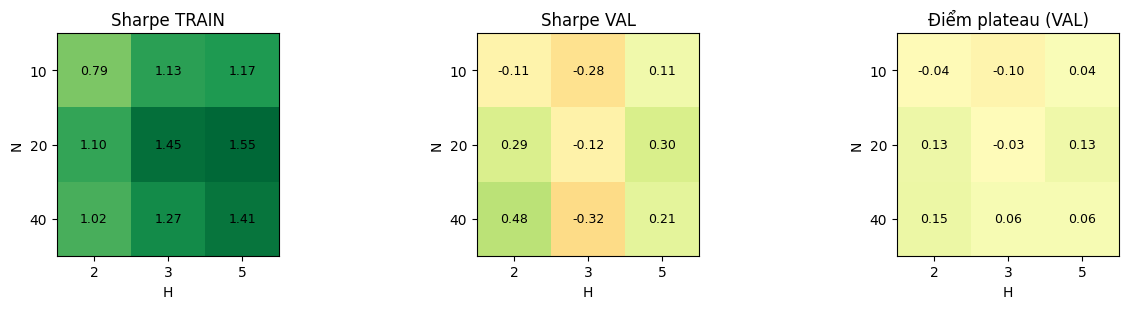

CAGR        max_dd        n_trades      sharpe       
period  train    val  train    val    train  val  train    val
N  H                                                          
10 2    0.029 -0.003 -0.082 -0.035     29.0  8.0  0.785 -0.112
   3    0.056 -0.008 -0.081 -0.045     24.0  7.0  1.130 -0.281
   5    0.075  0.003 -0.115 -0.031     25.0  6.0  1.173  0.108
20 2    0.036  0.005 -0.036 -0.019     24.0  6.0  1.101  0.285
   3    0.065 -0.003 -0.027 -0.023     19.0  5.0  1.451 -0.118
   5    0.084  0.009 -0.046 -0.020     18.0  4.0  1.549  0.304
40 2    0.032  0.009 -0.034 -0.012     18.0  5.0  1.018  0.478
   3    0.054 -0.008 -0.029 -0.024     15.0  5.0  1.273 -0.325
   5    0.074  0.006 -0.048 -0.021     14.0  4.0  1.415  0.209

In [20]:
def grid_eval(make_target, grid: dict, fixed: dict) -> pd.DataFrame:
    keys = list(grid)
    rows = []
    for vals in np.array(np.meshgrid(*grid.values(), indexing="ij")).reshape(len(keys), -1).T:
        cfg = {**fixed, **{k: type(grid[k][0])(v) for k, v in zip(keys, vals)}}
        res = backtest(dev, make_target(dev, **cfg))
        for p in ("train", "val"):
            s = perf_stats(res, *PERIODS[p])
            rows.append({**{k: cfg[k] for k in keys}, "period": p, **s})
    return pd.DataFrame(rows)


def plateau_pick(g: pd.DataFrame, a: str, b: str, metric: str = "sharpe") -> tuple[dict, pd.DataFrame]:
    tab = g[g.period == "val"].pivot(index=a, columns=b, values=metric)
    m = tab.to_numpy()
    score = np.full_like(m, np.nan)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            nb = [m[i, j]] + [m[x, y] for x, y in [(i - 1, j), (i + 1, j), (i, j - 1), (i, j + 1)]
                              if 0 <= x < m.shape[0] and 0 <= y < m.shape[1]]
            score[i, j] = np.nanmean(nb)
    score = pd.DataFrame(score, index=tab.index, columns=tab.columns)
    best = score.stack().sort_index(level=[0, 1], ascending=[False, True]).idxmax()   # hoà → a lớn, b nhỏ
    return {a: best[0], b: best[1]}, score


A1_FIXED = dict(vol_mult=1.2, short=False)
g1 = grid_eval(alpha1_breakout, {"N": [10, 20, 40], "H": [2, 3, 5]}, A1_FIXED)
pick1, score1 = plateau_pick(g1, "N", "H")
print("Config được chọn:", pick1)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a_, (title, tab) in zip(ax, [("Sharpe TRAIN", g1[g1.period == "train"].pivot(index="N", columns="H", values="sharpe")),
                                 ("Sharpe VAL", g1[g1.period == "val"].pivot(index="N", columns="H", values="sharpe")),
                                 ("Điểm plateau (VAL)", score1)]):
    im = a_.imshow(tab.to_numpy(float), cmap="RdYlGn", vmin=-1.5, vmax=1.5)
    a_.set_xticks(range(tab.shape[1]), tab.columns); a_.set_yticks(range(tab.shape[0]), tab.index)
    a_.set_xlabel("H"); a_.set_ylabel("N"); a_.set_title(title); a_.grid(False)
    for (i, j), v in np.ndenumerate(tab.to_numpy(float)):
        a_.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()
g1.pivot_table(index=["N", "H"], columns="period", values=["sharpe", "CAGR", "max_dd", "n_trades"]).round(3)

### 3.6 Độ ổn định của config được chọn

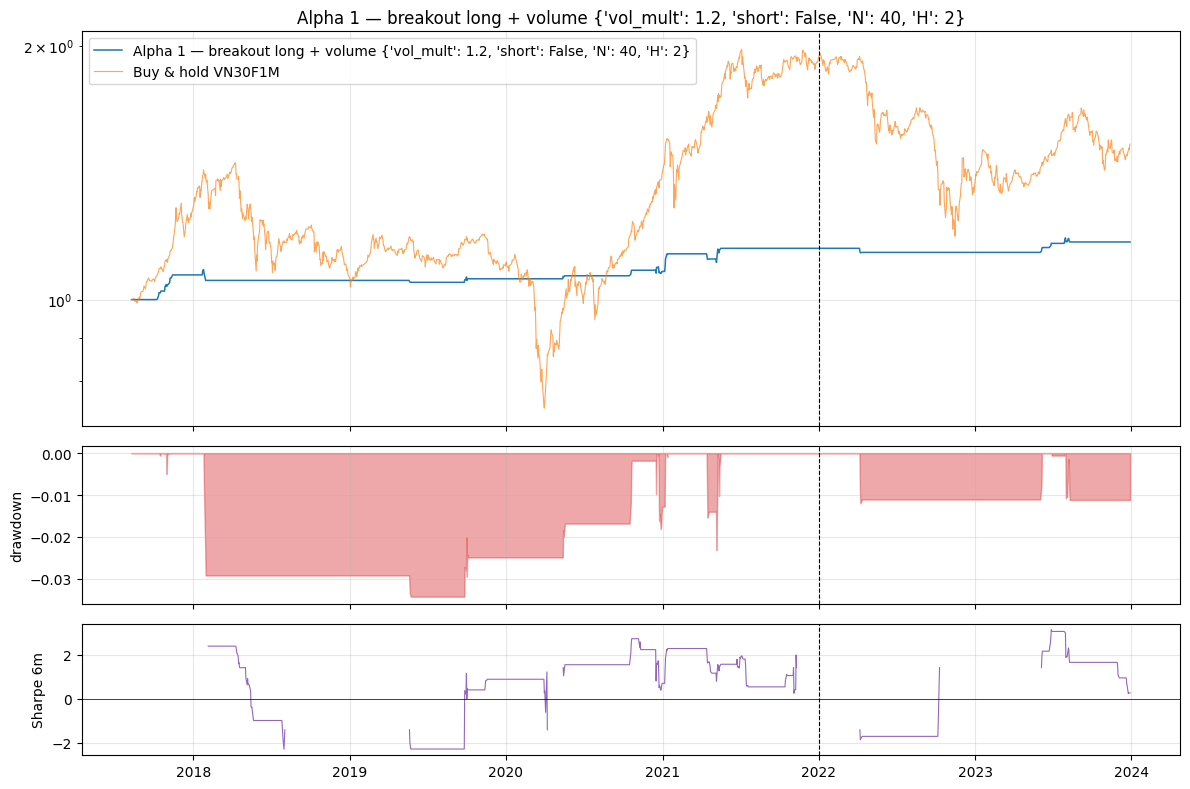

alpha1         buy&hold        
                 train     val    train     val
total_return     15.0%    1.7%    93.4%  -21.0%
CAGR              3.2%    0.9%    16.3%  -11.2%
ann_vol           3.2%    1.9%    23.1%   23.2%
sharpe            1.02    0.48     0.77   -0.40
sortino           2.17    0.80     1.05   -0.53
max_dd           -3.4%   -1.2%   -48.8%  -39.3%
max_dd_days     724.00  289.00   689.00  497.00
calmar            0.95    0.74     0.33   -0.29
t_stat            2.13    0.67     1.61   -0.56
pct_pos_months   15.1%    8.3%    58.5%   41.7%
n_trades         18.00    5.00    54.00   24.00
win_rate         66.7%   60.0%    61.1%   41.7%
avg_trade_bps    79.60   35.12   133.36  -67.49
profit_factor     3.01    2.48     1.90    0.67
avg_hold_days     2.78    2.40    19.65   19.21
exposure          4.7%    2.4%    99.9%  100.0%
cost_drag_ann     0.4%    0.2%     1.4%    1.2%

,return,sharpe,max_dd,exposure
date,,,,
2017,7.0%,4.74,-0.5%,17.8%
2018,-1.5%,-0.70,-2.9%,1.6%
2019,0.4%,0.29,-1.0%,3.2%
2020,2.0%,0.80,-1.8%,4.8%
2021,6.5%,1.28,-2.3%,4.0%
2022,-1.1%,-1.22,-1.2%,0.8%
2023,2.9%,1.17,-1.1%,4.0%


In [21]:
ALPHA1 = {**A1_FIXED, **{k: int(v) for k, v in pick1.items()}}
res_a1 = backtest(dev, alpha1_breakout(dev, **ALPHA1))
plot_result(res_a1, bench, title=f"Alpha 1 — breakout long + volume {ALPHA1}")
display(fmt(report({"alpha1": res_a1, "buy&hold": bench})))
yearly(res_a1).style.format({"return": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "exposure": "{:.1%}"})

In [22]:
# Độ nhạy chi phí trên validation: trượt giá ×2 và ×3. Alpha thật không được chết vì 0.3 điểm trượt giá.
sens = {}
for mult in [1, 2, 3]:
    spec = replace(VN30F, slippage=VN30F.slippage * mult)
    sens[f"slippage ×{mult}"] = backtest(dev, alpha1_breakout(dev, **ALPHA1), spec=spec)
fmt(report(sens, periods=("val",)).loc[["CAGR", "sharpe", "max_dd", "avg_trade_bps", "cost_drag_ann"]])

,slippage ×1,slippage ×2,slippage ×3
,val,val,val
CAGR,0.9%,0.8%,0.7%
sharpe,0.48,0.42,0.36
max_dd,-1.2%,-1.2%,-1.3%
avg_trade_bps,35.12,30.75,26.31
cost_drag_ann,0.2%,0.3%,0.5%


### 3.7 Kết luận Alpha 1

- **Train:** hypothesis đúng **một nửa**. Breakout tăng có lợi nhuận 2 phiên sau dương (t = 2.3–2.9 ở H=2). Breakdown thì **không** tiếp diễn: short lỗ, thị trường VN hay hồi sau phiên thủng đáy. Thêm volume xác nhận (phiên bản C) nâng Sharpe train từ 0.47 lên 1.10.
- **Validation:** cả 9 config đều có Sharpe val trong khoảng −0.3 đến 0.5. Config được chọn chỉ có **5 lệnh trong 2 năm**, t-stat 0.67. Sharpe rơi từ ~0.8–1.5 (train) xuống ~0 (val) trên toàn lưới, tức là edge của train không lặp lại.
- **Đã thử thêm (ghi để đếm số lần thử):** volume tổng F1M+F2M để khử méo chu kỳ roll, vì volume F1M ngày đáo hạn chỉ bằng 0.68× bình thường. Không cải thiện: t-stat train 3.20 → 3.05. Hạ ngưỡng volume xuống 1.0 thì edge gần như biến mất (excess 2–5 bps). Edge quá nhạy với ngưỡng là dấu hiệu overfit.
- **Quyết định: KHÔNG đưa Alpha 1 vào OOS.** Không nên đốt dữ liệu OOS cho một alpha chưa qua validation. Hướng tiếp: định nghĩa breakout trên **chỉ số VN30 spot** kèm độ rộng thị trường (breadth), hoặc gộp tín hiệu vào alpha khác thay vì dùng độc lập.

In [23]:
ALPHA1_PASSED_VAL = False

## 4. Alpha 2 — Basis hội tụ (HĐTL vs VN30)

### 4.1 Hypothesis

> **"Khi VN30F1M chiết khấu sâu so với VN30 (basis âm lớn), giá HĐTL có xu hướng tăng để hội tụ về chỉ số. Khi premium cao, HĐTL có xu hướng giảm."**

**Insight (đặc thù VN):**
- Basis **bắt buộc** về 0 lúc đáo hạn, vì giá thanh toán cuối cùng = VN30 close (đã thấy ở mục 1.3).
- Ở VN gần như **không bán khống được cổ phiếu**, nên mọi nhu cầu phòng hộ hoặc đặt cược giảm đều dồn vào HĐTL. Khi thị trường hoảng loạn, HĐTL bị bán quá tay xuống chiết khấu sâu.
- Arbitrage spot–futures gần như không làm được: không short được rổ VN30, ETF tạo/hoàn lô cồng kềnh, vốn lớn. Vì vậy basis lệch có thể kéo dài nhiều phiên thay vì bị arbitrage xoá ngay.
- Câu hỏi thực nghiệm: khi basis lệch, **HĐTL** về gần spot, hay **spot** đi theo HĐTL (HĐTL "dẫn dắt")? Chỉ trường hợp thứ nhất mới kiếm tiền được bằng cách giao dịch HĐTL.

### 4.2 Feature

- **F1 — basis %:** `(giá HĐ sẽ nắm giữ từ phiên sau − VN30) / VN30` tại close t. Ngày đáo hạn, HĐ nắm giữ từ phiên sau là F2M, nên dùng close của F2M.
- **F2 — carry/ngày:** `−basis% / số phiên còn lại tới đáo hạn`. Đây là tốc độ hội tụ kỳ vọng: cùng chiết khấu 0.5%, còn 2 phiên thì hấp dẫn hơn nhiều so với còn 20 phiên.
- Nhãn event study: lợi nhuận HĐTL từ open t+1 đến open t+1+H (giống Section 3).

In [24]:
def _expiry_schedule() -> pd.DatetimeIndex:
    """Ngày đáo hạn đã biết + quy tắc thứ Năm tuần 3 cho 2 tháng sau dữ liệu (lịch đáo hạn công bố trước, không phải lookahead)."""
    last = EXPIRIES[-1]
    extra = [third_thursday((last + pd.DateOffset(months=k)).year, (last + pd.DateOffset(months=k)).month) for k in (1, 2)]
    return EXPIRIES.append(pd.DatetimeIndex(extra))


EXP_ALL = _expiry_schedule()


def basis_features(b: pd.DataFrame) -> pd.DataFrame:
    exp = EXP_ALL.values
    is_exp = b["is_expiry"].to_numpy(bool)
    k = np.searchsorted(exp, b.index.values, side="left") + is_exp     # ngày đáo hạn → kỳ kế tiếp
    held_expiry = exp[np.minimum(k, len(exp) - 1)]
    dte = np.busday_count(b.index.values.astype("datetime64[D]"), held_expiry.astype("datetime64[D]"))
    basis = (b["next_contract_close"] - b["vn30"]) / b["vn30"]
    return pd.DataFrame({"basis_pct": basis, "dte": dte, "carry": -basis / np.maximum(dte, 1)}, index=b.index)


bf_train = basis_features(train)
bf_train.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
basis_pct,1101.0,-0.0024,0.0099,-0.0617,-0.0060,-0.0014,0.0025,0.0573
dte,1103.0,11.4995,6.5996,1.0000,6.0000,11.0000,17.0000,25.0000
carry,1101.0,0.0003,0.0014,-0.0084,-0.0003,0.0001,0.0007,0.0181


### 4.3 Kiểm định trên TRAIN

Chia basis thành 5 nhóm (ngưỡng nhóm tính **trên train**). Q1 = chiết khấu sâu nhất, Q5 = premium cao nhất. Bảng thứ hai tách lợi nhuận phiên sau thành phần của **spot** và của **HĐTL**, để xem bên nào di chuyển về bên nào.

In [25]:
q_train = pd.qcut(bf_train.basis_pct, 5, labels=[f"Q{i}" for i in range(1, 6)])
tab = {}
for H in [1, 2, 3]:
    fwd = fwd_return(train, H)
    g = fwd.groupby(q_train, observed=True)
    tab[f"H={H} mean_bps"] = g.mean() * 1e4
    tab[f"H={H} t"] = g.mean() / g.std() * np.sqrt(g.count())
es2 = pd.DataFrame(tab)
es2.insert(0, "basis_TB_bps", bf_train.basis_pct.groupby(q_train, observed=True).mean() * 1e4)
display(es2.round(2))

nxt = pd.DataFrame({
    "spot_t+1_bps": (train.vn30.shift(-1) / train.vn30 - 1),
    "futures_t+1_bps": train.ret_cc.shift(-1),
}).groupby(q_train, observed=True).mean() * 1e4
nxt.round(1)

,basis_TB_bps,H=1 mean_bps,H=1 t,H=2 mean_bps,H=2 t,H=3 mean_bps,H=3 t
basis_pct,,,,,,,
Q1,-163.51,34.09,2.50,57.50,3.21,96.38,4.35
Q2,-48.75,6.40,0.57,8.27,0.59,19.40,1.11
Q3,-14.00,15.43,2.01,25.99,2.56,25.90,2.00
Q4,16.67,1.15,0.13,14.34,1.19,15.89,1.02
Q5,89.04,-13.18,-1.24,-18.87,-1.17,-24.07,-1.18


,spot_t+1_bps,futures_t+1_bps
basis_pct,,
Q1,6.1,37.0
Q2,-4.3,13.9
Q3,5.8,9.5
Q4,13.9,0.1
Q5,15.2,-16.6


**Đọc kết quả train:** quan hệ gần như **đơn điệu**. Chiết khấu sâu (Q1) → HĐTL tăng mạnh nhất phiên sau. Premium cao (Q5) → HĐTL giảm. Phần lớn chuyển động đến từ **HĐTL**, spot gần như không đi theo. Nghĩa là HĐTL hội tụ về spot chứ không phải ngược lại, và đây là trường hợp giao dịch được.

### 4.4 Rule → chuỗi position −1/0/1

Tín hiệu đánh giá lại mỗi ngày (H = 1: target hôm nay = tín hiệu hôm nay; tín hiệu giữ nguyên thì vị thế giữ nguyên, không tốn phí).
- **A. Basis tuyệt đối:** long nếu `basis% < −θ`, short nếu `basis% > +θ`, còn lại flat. θ = 0.5%.
- **B. Carry:** long nếu `carry > θ_c`, short nếu `carry < −θ_c`. θ_c = 5 bps/ngày.

Cả hai đều là −1/0/1 thật, vì cả hai chân long/short đều có cơ sở kinh tế (hội tụ hai chiều).

In [26]:
def alpha2_basis(b: pd.DataFrame, feature: str = "basis", theta: float = 0.005, H: int = 1) -> pd.Series:
    f = basis_features(b)
    if feature == "basis":
        ev = np.select([f.basis_pct < -theta, f.basis_pct > theta], [1, -1], 0)
    else:
        ev = np.select([f.carry > theta, f.carry < -theta], [1, -1], 0)
    ev = pd.Series(ev, index=b.index).where(f.basis_pct.notna(), 0)     # 23–24/01/2018: không có VN30 → đứng ngoài
    return hold_after_event(ev, H)


A2_VERSIONS = {
    "A: basis θ=0.5%": dict(feature="basis", theta=0.005, H=1),
    "B: carry θ=5bps/ngày": dict(feature="carry", theta=0.0005, H=1),
}
a2_res = {k: backtest(dev, alpha2_basis(dev, **cfg)) for k, cfg in A2_VERSIONS.items()}
assert all(assert_causal(alpha2_basis, cfg) for cfg in A2_VERSIONS.values())
print("✓ alpha2 không lookahead (3 điểm cắt)")
fmt(report({**a2_res, "buy&hold": bench}, periods=("train",)))

✓ alpha2 không lookahead (3 điểm cắt)


,A: basis θ=0.5%,B: carry θ=5bps/ngày,buy&hold
,train,train,train
total_return,79.3%,177.0%,93.4%
CAGR,14.3%,26.2%,16.3%
ann_vol,16.7%,16.9%,23.1%
sharpe,0.88,1.46,0.77
sortino,1.32,2.29,1.05
max_dd,-22.8%,-20.6%,-48.8%
max_dd_days,168.00,121.00,689.00
calmar,0.63,1.27,0.33
t_stat,1.85,3.06,1.61


Logic chốt từ train: **phiên bản B (carry)**. Carry tốt hơn basis tuyệt đối ở mọi chỉ số chính (Sharpe 1.46 vs 0.88, t 3.06 vs 1.85), và có lý do kinh tế: nó chuẩn hoá theo thời gian còn lại tới đáo hạn.

### 4.5 VALIDATION — lưới nhỏ khai báo trước

- θ_c ∈ {3, 5, 10} bps/ngày × H ∈ {1, 2, 3}, tổng **9 config**. Cùng quy tắc chọn plateau như Alpha 1.
- Điều kiện qua validation (giống Alpha 1): Sharpe val > 0.5, ổn định theo năm, chịu được chi phí ×2.

Config được chọn: {'theta': 0.0005, 'H': 3}


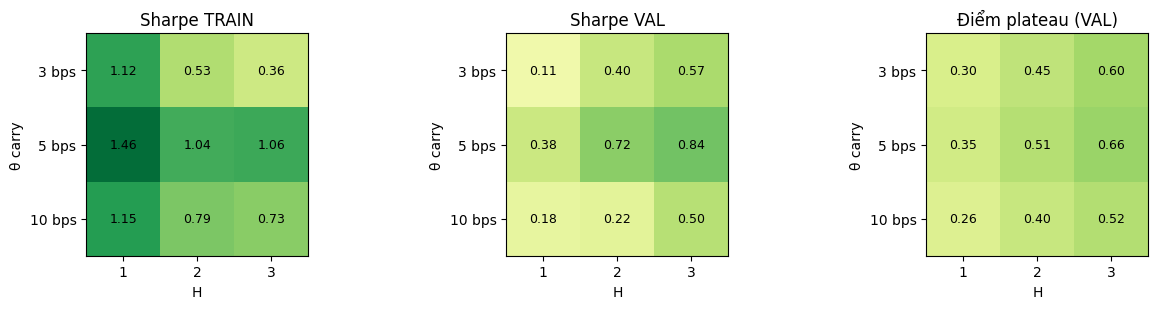

CAGR        max_dd        n_trades        sharpe       
period    train    val  train    val    train    val  train    val
theta  H                                                          
0.0003 1  0.219  0.003 -0.266 -0.218    252.0  108.0  1.117  0.106
       2  0.095  0.063 -0.280 -0.206    227.0   98.0  0.531  0.403
       3  0.058  0.106 -0.318 -0.166    208.0   88.0  0.365  0.573
0.0005 1  0.262  0.051 -0.206 -0.115    197.0   90.0  1.461  0.380
       2  0.196  0.125 -0.210 -0.146    191.0   87.0  1.041  0.719
       3  0.213  0.157 -0.238 -0.163    183.0   83.0  1.059  0.837
0.0010 1  0.154  0.015 -0.187 -0.109    124.0   45.0  1.150  0.177
       2  0.113  0.021 -0.237 -0.122    142.0   56.0  0.788  0.219
       3  0.113  0.072 -0.245 -0.119    139.0   58.0  0.732  0.495

In [27]:
g2 = grid_eval(alpha2_basis, {"theta": [0.0003, 0.0005, 0.001], "H": [1, 2, 3]}, dict(feature="carry"))
pick2, score2 = plateau_pick(g2, "theta", "H")
print("Config được chọn:", pick2)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a_, (title, tab) in zip(ax, [("Sharpe TRAIN", g2[g2.period == "train"].pivot(index="theta", columns="H", values="sharpe")),
                                 ("Sharpe VAL", g2[g2.period == "val"].pivot(index="theta", columns="H", values="sharpe")),
                                 ("Điểm plateau (VAL)", score2)]):
    a_.imshow(tab.to_numpy(float), cmap="RdYlGn", vmin=-1.5, vmax=1.5)
    a_.set_xticks(range(tab.shape[1]), tab.columns); a_.set_yticks(range(tab.shape[0]), [f"{v * 1e4:.0f} bps" for v in tab.index])
    a_.set_xlabel("H"); a_.set_ylabel("θ carry"); a_.set_title(title); a_.grid(False)
    for (i, j), v in np.ndenumerate(tab.to_numpy(float)):
        a_.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()
g2.pivot_table(index=["theta", "H"], columns="period", values=["sharpe", "CAGR", "max_dd", "n_trades"]).round(3)

### 4.6 Độ ổn định của config được chọn

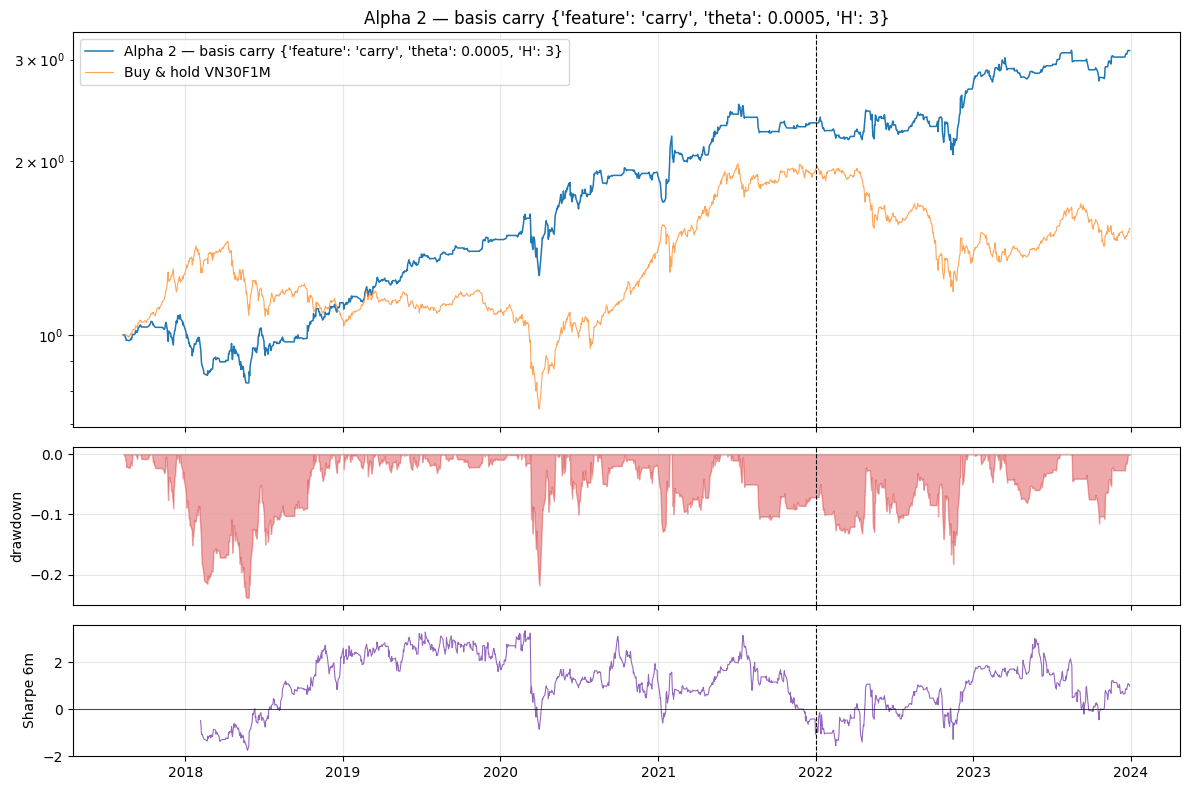

alpha2         buy&hold        
                 train     val    train     val
total_return    133.1%   33.5%    93.4%  -21.0%
CAGR             21.3%   15.7%    16.3%  -11.2%
ann_vol          20.2%   19.8%    23.1%   23.2%
sharpe            1.06    0.84     0.77   -0.40
sortino           1.58    1.28     1.05   -0.53
max_dd          -23.8%  -16.3%   -48.8%  -39.3%
max_dd_days     210.00  152.00   689.00  497.00
calmar            0.90    0.96     0.33   -0.29
t_stat            2.22    1.18     1.61   -0.56
pct_pos_months   66.0%   54.2%    58.5%   41.7%
n_trades        183.00   83.00    54.00   24.00
win_rate         54.1%   53.0%    61.1%   41.7%
avg_trade_bps    51.11   39.60   133.36  -67.49
profit_factor     1.65    1.46     1.90    0.67
avg_hold_days     3.76    3.37    19.65   19.21
exposure         67.2%   61.0%    99.9%  100.0%
cost_drag_ann     3.9%    3.4%     1.4%    1.2%

,return,sharpe,max_dd,exposure
date,,,,
2017,3.6%,0.63,-9.0%,75.2%
2018,9.7%,0.53,-18.6%,74.4%
2019,28.7%,2.38,-3.7%,70.4%
2020,28.8%,1.12,-21.7%,71.4%
2021,23.7%,1.15,-10.9%,49.2%
2022,15.1%,0.69,-16.3%,72.7%
2023,15.9%,1.25,-11.5%,49.4%


In [28]:
ALPHA2 = {"feature": "carry", "theta": float(pick2["theta"]), "H": int(pick2["H"])}
res_a2 = backtest(dev, alpha2_basis(dev, **ALPHA2))
plot_result(res_a2, bench, title=f"Alpha 2 — basis carry {ALPHA2}")
display(fmt(report({"alpha2": res_a2, "buy&hold": bench})))
yearly(res_a2).style.format({"return": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "exposure": "{:.1%}"})

In [29]:
# (a) Tách chân long / short — alpha có sống nhờ một phía (ví dụ chỉ nhờ long trong thị trường tăng) không?
_t2 = alpha2_basis(dev, **ALPHA2)
legs = {"chỉ chân long": backtest(dev, _t2.clip(lower=0)), "chỉ chân short": backtest(dev, _t2.clip(upper=0)),
        "cả hai": res_a2}
display(fmt(report(legs)).loc[["CAGR", "sharpe", "max_dd", "n_trades", "exposure"]])

# (b) Có phải chỉ là beta thị trường? Hồi quy lợi nhuận ngày của alpha lên buy&hold
for p in ("train", "val"):
    y, x = period(res_a2.daily.ret, p), period(bench.daily.ret, p)
    beta = np.cov(y, x)[0, 1] / x.var()
    alpha_ann = (y - beta * x).mean() * TRADING_DAYS
    print(f"{p}: corr với buy&hold = {y.corr(x):+.2f}, beta = {beta:+.2f}, alpha sau khi trừ beta = {alpha_ann:.1%}/năm")

chỉ chân long         chỉ chân short         cả hai        
                 train     val          train    val   train     val
CAGR             17.7%    5.6%           3.0%   9.3%   21.3%   15.7%
sharpe            1.10    0.39           0.30   1.34    1.06    0.84
max_dd          -23.3%  -19.6%         -19.7%  -4.2%  -23.8%  -16.3%
n_trades         99.00   52.00          84.00  31.00  183.00   83.00
exposure         42.8%   51.2%          24.4%   9.8%   67.2%   61.0%

train: corr với buy&hold = +0.22, beta = +0.20, alpha sau khi trừ beta = 17.9%/năm
val: corr với buy&hold = +0.62, beta = +0.53, alpha sau khi trừ beta = 21.4%/năm


In [30]:
# (c) Độ nhạy chi phí trên validation
sens2 = {f"slippage ×{m}": backtest(dev, _t2, spec=replace(VN30F, slippage=VN30F.slippage * m)) for m in [1, 2, 3]}
sens2["phí môi giới 0đ"] = backtest(dev, _t2, spec=replace(VN30F, fee_fixed=2_700 + 2_550))
fmt(report(sens2, periods=("val",)).loc[["CAGR", "sharpe", "max_dd", "avg_trade_bps", "cost_drag_ann"]])

,slippage ×1,slippage ×2,slippage ×3,phí môi giới 0đ
,val,val,val,val
CAGR,15.7%,13.6%,11.4%,15.8%
sharpe,0.84,0.74,0.64,0.84
max_dd,-16.3%,-17.1%,-18.1%,-16.4%
avg_trade_bps,39.60,35.30,30.41,39.86
cost_drag_ann,3.4%,5.1%,6.9%,3.2%


## 5. Scorecard trước OOS — alpha nào đủ điều kiện kiểm chứng?

Tiêu chí khai báo trước (áp dụng giống nhau cho mọi alpha):

| # | Tiêu chí | Lý do |
|---|---|---|
| 1 | Sharpe val > 0.5 | có edge sau phí ở dữ liệu chưa dùng để thiết kế |
| 2 | Sharpe val ≥ 50% Sharpe train | không suy giảm quá mạnh (dấu hiệu overfit) |
| 3 | ≥ 30 lệnh ở val | đủ mẫu để con số có nghĩa |
| 4 | Sharpe val > 0.3 khi trượt giá ×2 | sống được với chi phí thực tế xấu hơn |
| 5 | ≥ 70% số năm (train + val) có lãi | ổn định, không sống nhờ 1 năm đột biến |

In [31]:
def scorecard(name: str, make_target, cfg: dict) -> dict:
    res = backtest(dev, make_target(dev, **cfg))
    tr, va = perf_stats(res, *PERIODS["train"]), perf_stats(res, *PERIODS["val"])
    va_x2 = perf_stats(backtest(dev, make_target(dev, **cfg), spec=replace(VN30F, slippage=2 * VN30F.slippage)), *PERIODS["val"])
    yr = yearly(res)
    checks = {
        "1. Sharpe val > 0.5": va["sharpe"] > 0.5,
        "2. Sharpe val ≥ 50% train": va["sharpe"] >= 0.5 * tr["sharpe"],
        "3. ≥ 30 lệnh ở val": va["n_trades"] >= 30,
        "4. Sharpe val (slip ×2) > 0.3": va_x2["sharpe"] > 0.3,
        "5. ≥ 70% năm có lãi": (yr["return"] > 0).mean() >= 0.7,
    }
    return {"alpha": name, "config": cfg, "sharpe_train": tr["sharpe"], "sharpe_val": va["sharpe"],
            "n_trades_val": va["n_trades"], "sharpe_val_slip2": va_x2["sharpe"],
            "years_positive": f"{int((yr['return'] > 0).sum())}/{len(yr)}", **checks, "PASS": all(checks.values())}


CANDIDATES = {
    "alpha1_breakout": (alpha1_breakout, ALPHA1),
    "alpha2_basis_carry": (alpha2_basis, ALPHA2),
}
sc = pd.DataFrame([scorecard(n, fn, cfg) for n, (fn, cfg) in CANDIDATES.items()]).set_index("alpha")
OOS_CANDIDATES = {n: CANDIDATES[n] for n in sc.index[sc.PASS]}
print("Đủ điều kiện OOS:", list(OOS_CANDIDATES))
sc.T

Đủ điều kiện OOS: ['alpha2_basis_carry']


alpha,alpha1_breakout,alpha2_basis_carry
config,"{'vol_mult': 1.2, 'short': False, 'N': 40, 'H'...","{'feature': 'carry', 'theta': 0.0005, 'H': 3}"
sharpe_train,1.018476,1.058884
sharpe_val,0.47775,0.836757
n_trades_val,5,83
sharpe_val_slip2,0.418334,0.742162
years_positive,5/7,7/7
1. Sharpe val > 0.5,False,True
2. Sharpe val ≥ 50% train,False,True
3. ≥ 30 lệnh ở val,False,True
4. Sharpe val (slip ×2) > 0.3,True,True


In [32]:
# Tương quan hai alpha trên validation — tham khảo cho bước gộp danh mục sau này
_r1, _r2 = backtest(dev, alpha1_breakout(dev, **ALPHA1)).daily.ret, res_a2.daily.ret
print(f"Tương quan lợi nhuận ngày alpha1 vs alpha2 — train: {period(_r1, 'train').corr(period(_r2, 'train')):+.2f}, "
      f"val: {period(_r1, 'val').corr(period(_r2, 'val')):+.2f}")

Tương quan lợi nhuận ngày alpha1 vs alpha2 — train: +0.01, val: +0.02


## 6. TEST / OOS — kiểm chứng MỘT LẦN

**Quy trình:**
1. Config đã chốt ở Section 3–5 (`ALPHA1`, `ALPHA2`). **Không sửa gì nữa.**
2. Đặt `RUN_OOS = True` ở cell dưới rồi chạy cell đó **một lần**.
3. `run_oos_once()` ghi config, hash và metrics vào `oos_ledger.json`. Lần sau chạy lại:
   - cùng config → chỉ hiển thị lại kết quả đã ghi, không tính lại;
   - config khác → **bị từ chối**. Muốn kiểm chứng config mới thì cần dữ liệu OOS mới (ví dụ năm 2026 sau khi kết thúc), không được dùng lại 2024–2025.
4. Kết quả OOS xấu thì **chấp nhận**. Không quay lại tune rồi chạy lại OOS, vì làm vậy OOS trở thành validation thứ hai.

Feature của giai đoạn test được tính trên toàn chuỗi 2017–2025 để có warm-up, nhưng tất cả đều nhân quả (đã kiểm bằng `assert_causal`).

In [33]:
RUN_OOS = False   # ⚠️ chỉ bật 1 lần, sau khi đã đọc kỹ Section 5


def _cfg_hash(name: str, cfg: dict) -> str:
    blob = json.dumps({"name": name, "cfg": cfg, "spec": asdict(VN30F), "periods": PERIODS}, sort_keys=True, default=str)
    return hashlib.sha256(blob.encode()).hexdigest()[:16]


def run_oos_once(name: str, make_target, cfg: dict, confirm: bool = False) -> pd.Series:
    ledger = json.loads(OOS_LEDGER.read_text()) if OOS_LEDGER.exists() else {}
    h = _cfg_hash(name, cfg)
    if name in ledger:
        e = ledger[name]
        if e["config_hash"] != h:
            raise RuntimeError(f"{name}: OOS đã dùng ngày {e['run_at']} với config {e['config']}. "
                               "Không được chạy lại OOS với config khác.")
        print(f"{name}: hiển thị lại kết quả OOS đã ghi ngày {e['run_at']} (không tính lại).")
        return pd.Series(e["metrics"], name=name)
    if not confirm:
        raise OOSLocked("Đặt RUN_OOS = True để chạy OOS (một lần).")
    _OOS["unlocked"] = True
    try:
        res = backtest(bars, make_target(bars, **cfg))
        bh = backtest(bars, pd.Series(1, index=bars.index))
        m, mb = perf_stats(res, *PERIODS["test"]), perf_stats(bh, *PERIODS["test"])
        plot_result(res, bh, title=f"OOS {name} — {cfg}", end=PERIODS["test"][1])
    finally:
        _OOS["unlocked"] = False
    ledger[name] = {"config": cfg, "config_hash": h, "run_at": datetime.now().isoformat(timespec="seconds"),
                    "test_period": PERIODS["test"], "metrics": m, "buy_and_hold": mb}
    OOS_LEDGER.write_text(json.dumps(ledger, indent=2, ensure_ascii=False, default=float))
    print(f"✓ Đã ghi kết quả OOS của {name} vào {OOS_LEDGER.name}")
    return pd.Series(m, name=name)


if RUN_OOS:
    oos = pd.concat([run_oos_once(n, fn, cfg, confirm=True) for n, (fn, cfg) in OOS_CANDIDATES.items()], axis=1)
    display(fmt(oos))
else:
    _done = json.loads(OOS_LEDGER.read_text()) if OOS_LEDGER.exists() else {}
    print("🔒 OOS đang khoá. Đã chạy OOS cho:", list(_done) or "chưa có alpha nào",
          "| Ứng viên đang chờ:", [n for n in OOS_CANDIDATES if n not in _done])

🔒 OOS đang khoá. Đã chạy OOS cho: chưa có alpha nào | Ứng viên đang chờ: ['alpha2_basis_carry']


## 7. Nhật ký nghiên cứu & bước tiếp theo

**Số lần thử (để tự đánh giá rủi ro overfit):**

| Alpha | Giai đoạn | Đã thử |
|---|---|---|
| 1 — breakout | train | event study 3 N × 4 H × 2 chiều; 3 phiên bản rule (A/B/C). Ngoài notebook còn khám phá 6 biến thể F1: close>max close, close>max high, +volume, +CLV>0.7, breakout đầu tiên trong 5 phiên, vượt 0.5×ATR. Thêm volume tổng F1M+F2M và ngưỡng 1.0/1.2. |
| 1 — breakout | val | 9 config (N × H) |
| 2 — basis | train | quintile basis × 3 H; carry với ngưỡng 5/10/20 bps; 2 phiên bản rule (A/B) |
| 2 — basis | val | 9 config (θ × H) |

**Rủi ro đã biết của Alpha 2:**
- Train và val **không đồng thuận về H**: train tốt nhất ở H=1, val tốt nhất ở H=3. Config chọn theo plateau của val (H=3) có Sharpe train 1.06, thấp hơn mức 1.46 của H=1.
- t-stat ở val chỉ khoảng 1.2 (2 năm dữ liệu). Edge chưa có ý nghĩa thống kê nếu chỉ xét riêng val.
- Chi phí ăn mất khoảng 3.4–3.9%/năm (tính trên equity), khoảng 7%/năm nếu trượt giá ×3. Edge phụ thuộc trượt giá thực tế, cần đo bằng lệnh thật (paper trading).
- Chân short mạnh ở val (2022 giảm sâu), chân long mạnh ở train. Hai chân luân phiên gánh nhau.

**Bước tiếp theo (xem `README.md`):** chạy OOS một lần → paper trading trên dữ liệu 2026 → alpha cổ phiếu (cần dữ liệu không survivorship bias, ràng buộc T+2.5 đã có sẵn trong framework) → gộp danh mục nhiều alpha.